# Revised joint Transformer: diagnosis, implementation and measured evaluation

This is a **separate revision** of `NLP_Final_project.ipynb`. The original notebook and the completed BiLSTM evidence are preserved. The baseline reproduces the supplied 4,345,243-parameter architecture; the revised default has **19,748,595 total parameters**, including its task embeddings, character features, both heads, intent context and CRF. Both are single jointly trained systems with randomly initialized encoders. Only word embeddings may use permitted pretrained vectors.

Run status and actual metrics come from the genuine outputs and final completion ledger. Larger capacity is a hypothesis, not evidence of improved accuracy. Historical evaluator-v1 scores are not comparison targets. All decisions use the original development split and the shared `exact_character_span_v2` evaluator.

## Run instructions

Use the repository's pinned Python 3.12/CUDA environment and **SC4002 (.venv)** kernel. Launch Jupyter with `PYTHONHASHSEED=42` and `CUBLAS_WORKSPACE_CONFIG=:4096:8`. Copy this file into a fresh folder, keep its name **NLP_Final_project_revised.ipynb**, save edits to the labelled configuration cell, and Restart Kernel and Run All. The notebook embeds all implementation code and needs no repository modules at runtime. It downloads original English data and allowed Word2Vec initialization if verified caches are not supplied.

The default is **development-only**: no learned model is evaluated on test. After choosing settings, set `evaluate_test=True` and perform a new full run for the final four-row table. Never select settings using test scores. Each run exclusively creates `transformer_run_artifacts/` and never resumes/overwrites a completed run.

**AI history:** the brief requires Stage 1 without generative AI; assistance occurred at the user's request and no lecturer exception is claimed. This revision's analysis, implementation and verification used Codex. Group information and verified human contributions remain pending; do not invent them.

In [1]:
import os
from pathlib import Path
if os.environ.get('PYTHONHASHSEED') != '42':
    raise RuntimeError('Launch a fresh Jupyter kernel with PYTHONHASHSEED=42 before Run All')
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
if os.environ['CUBLAS_WORKSPACE_CONFIG'] != ':4096:8':
    raise RuntimeError('Restart with CUBLAS_WORKSPACE_CONFIG=:4096:8')
NOTEBOOK_PATH = Path.cwd() / 'NLP_Final_project_revised.ipynb'
if not NOTEBOOK_PATH.is_file():
    raise FileNotFoundError('Keep the revised filename and kernel working directory together')
RUN_ROOT = Path.cwd() / 'transformer_run_artifacts'
RUN_ROOT.mkdir(exist_ok=False)
os.environ['MPLCONFIGDIR'] = str(RUN_ROOT / 'matplotlib_cache')


## Editable configuration

Only this cell accepts ordinary literal dictionary edits without rebuilding or changing hashes. Save before running. Both models use the same initialization matrix, data, scorer and development selection rule. The new common training protocol uses complete budgets, two AdamW learning rates, warmup/cosine decay, gradient clipping and globally normalized losses. It is not an exact reproduction of the original 12-epoch training procedure.

Use `embedding_source='word2vec'` to retain the original allowed initialization; missing assets raise rather than silently switching to random. `random` is an explicit alternative experiment. No full pretrained vocabulary enters prediction: only the train-fitted 5,300-by-300 table is retained and counted. Set cache paths if desired, or use the terminal executor's cache flags. Each run archives an exact copy of original English data.

In [2]:
RUNTIME = {'seed': 42, 'deterministic_algorithms': True, 'precision': 'float32'}

STAGE1_CONFIG = {'model': {'word_dim': 300,
           'd_model': 256,
           'n_heads': 4,
           'n_layers': 4,
           'd_ff': 768,
           'dropout': 0.15,
           'char_dim': 32,
           'char_channels': 64,
           'char_kernels': (3, 4, 5),
           'intent_context_dim': 64,
           'attention_pool_dim': 128,
           'head_hidden_dim': 256,
           'use_char': False,
           'use_crf': False,
           'use_intent_context': False,
           'use_attention_pool': False,
           'use_input_norm': False,
           'independent_init': False},
 'training': {'max_epochs': 20,
              'batch_size': 32,
              'learning_rate': 0.0005,
              'embedding_learning_rate': 0.0001,
              'weight_decay': 0.01,
              'gradient_clip_norm': 1.0,
              'warmup_fraction': 0.1,
              'min_lr_ratio': 0.1}}

STAGE2_CONFIG = {'model': {'word_dim': 300,
           'd_model': 512,
           'n_heads': 8,
           'n_layers': 6,
           'd_ff': 1792,
           'dropout': 0.25,
           'char_dim': 32,
           'char_channels': 64,
           'char_kernels': (3, 4, 5),
           'intent_context_dim': 64,
           'attention_pool_dim': 128,
           'head_hidden_dim': 256,
           'use_char': True,
           'use_crf': True,
           'use_intent_context': True,
           'use_attention_pool': True,
           'use_input_norm': True,
           'independent_init': True},
 'training': {'max_epochs': 20,
              'batch_size': 32,
              'learning_rate': 0.0005,
              'embedding_learning_rate': 0.0001,
              'weight_decay': 0.01,
              'gradient_clip_norm': 1.0,
              'warmup_fraction': 0.1,
              'min_lr_ratio': 0.1}}

RUN_OPTIONS = {'evaluate_test': False,
 'device': 'cuda',
 'dataset_path': None,
 'embedding_source': 'word2vec',
 'embedding_archive': None,
 'verification_timeout_seconds': 600}


In [3]:
"""Tokenizer-independent scoring and pinned MASSIVE data shared by both notebooks.

This module intentionally uses only the Python standard library so its exact
source can be embedded in a standalone submission notebook. Scores are fractions.
Character offsets refer to the original Python Unicode string, with exclusive
ends. The recorded data digest pins the project's original release bytes; it is
not an independently published authenticity certificate.
"""

import hashlib
import json
import os
from pathlib import Path
import re
import tarfile
import tempfile
from urllib.request import Request, urlopen


EVALUATOR_VERSION = "exact_character_span_v2"
DATASET_SHA256 = "c70f75c6a543a26e249ec383df67733ad9b1066f6c0406c2e04a3f03356e407e"
EXPECTED_COUNTS = {"train": 11514, "dev": 2033, "test": 2974}
SOURCE_URL = "https://amazon-massive-nlu-dataset.s3.amazonaws.com/amazon-massive-dataset-1.0.tar.gz"
ENGLISH_MEMBER = "1.0/data/en-US.jsonl"
_CONTRACT_ANNOTATION = re.compile(r"\[([A-Za-z_][A-Za-z_0-9]*)[ \t]*:[ \t]*(.*?)\]", re.DOTALL)
_CONTRACT_MAX_BYTES = 128 * 1024 * 1024


def _contract_json_hash(value):
    data = json.dumps(value, ensure_ascii=False, sort_keys=True, separators=(",", ":"))
    return hashlib.sha256(data.encode("utf-8")).hexdigest()


def parse_annotated_spans(utt, annot_utt):
    """Strip annotation syntax only, requiring exact original-text reconstruction."""
    if not isinstance(utt, str) or not isinstance(annot_utt, str):
        raise TypeError("Utterance and annotated utterance must be strings")
    pieces, spans = [], []
    annotation_cursor = plain_cursor = 0
    for match in _CONTRACT_ANNOTATION.finditer(annot_utt):
        before = annot_utt[annotation_cursor:match.start()]
        pieces.append(before)
        plain_cursor += len(before)
        text = match.group(2)
        if not text:
            raise ValueError("An annotated slot cannot have empty text")
        spans.append({"slot_type": match.group(1), "text": text,
                      "start": plain_cursor, "end": plain_cursor + len(text)})
        pieces.append(text)
        plain_cursor += len(text)
        annotation_cursor = match.end()
    pieces.append(annot_utt[annotation_cursor:])
    if "".join(pieces) != utt:
        raise ValueError("Removing annotation syntax does not exactly reconstruct utt")
    return spans


def load_verified_massive(path):
    """Load only the pinned original bytes, preserving every partition and row."""
    path = Path(path)
    if path.is_symlink() or not path.is_file():
        raise ValueError("Dataset must be a regular, non-symlink file")
    if not 0 < path.stat().st_size <= _CONTRACT_MAX_BYTES:
        raise ValueError("Dataset size is outside the accepted range")
    raw = path.read_bytes()
    observed_hash = hashlib.sha256(raw).hexdigest()
    if observed_hash != DATASET_SHA256:
        raise ValueError("Dataset SHA256 differs from the pinned original release; refusing reuse")
    splits = {name: [] for name in EXPECTED_COUNTS}
    seen = set()
    for number, line in enumerate(raw.decode("utf-8").splitlines(), 1):
        if not line.strip():
            raise ValueError(f"Blank dataset row at line {number}")
        row = json.loads(line)
        if not isinstance(row, dict):
            raise ValueError(f"Dataset row {number} is not an object")
        for field in ("id", "utt", "intent", "annot_utt", "partition", "locale"):
            if not isinstance(row.get(field), str) or (field != "annot_utt" and not row[field]):
                raise ValueError(f"Invalid dataset field {field!r} at line {number}")
        if row["locale"] != "en-US" or row["partition"] not in splits:
            raise ValueError(f"Unexpected locale or partition at line {number}")
        if row["id"] in seen:
            raise ValueError(f"Duplicate dataset ID: {row['id']!r}")
        seen.add(row["id"])
        parse_annotated_spans(row["utt"], row["annot_utt"])
        splits[row["partition"]].append(row)
    counts = {name: len(rows) for name, rows in splits.items()}
    if counts != EXPECTED_COUNTS:
        raise ValueError(f"Original split counts differ: {counts!r}")
    manifest = {
        "evaluator_version": EVALUATOR_VERSION,
        "dataset_sha256": observed_hash,
        "source_url": SOURCE_URL,
        "archive_member": ENGLISH_MEMBER,
        "counts": counts,
        "split_id_sha256": {name: _contract_json_hash([row["id"] for row in rows])
                            for name, rows in splits.items()},
        "split_content_sha256": {name: _contract_json_hash(rows)
                                 for name, rows in splits.items()},
        "identity_scope": "Pinned original bytes; original row order and every record field retained",
    }
    return splits, manifest


def ensure_verified_massive(path):
    """Reuse verified data or safely stream its exact member from the official URL.

    Existing mismatched files are never overwritten. A verified temporary file
    is published using an exclusive atomic hard link; archive-controlled names
    are never used for filesystem writes and extract/extractall are not used.
    """
    path = Path(path)
    if path.exists() or path.is_symlink():
        return load_verified_massive(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    descriptor, temporary_name = tempfile.mkstemp(prefix=".massive-verified-", suffix=".part", dir=path.parent)
    temporary = Path(temporary_name)
    try:
        found = False
        with os.fdopen(descriptor, "wb") as output:
            request = Request(SOURCE_URL, headers={"User-Agent": "SC4002-verified-comparison/2"})
            with urlopen(request, timeout=60) as response, tarfile.open(fileobj=response, mode="r|gz") as archive:
                for member in archive:
                    if member.name != ENGLISH_MEMBER:
                        continue
                    if not member.isfile() or not 0 < member.size <= _CONTRACT_MAX_BYTES:
                        raise ValueError("English archive member must be a bounded regular file")
                    source = archive.extractfile(member)
                    if source is None:
                        raise ValueError("English archive member could not be read")
                    written = 0
                    with source:
                        for block in iter(lambda: source.read(1024 * 1024), b""):
                            written += len(block)
                            if written > member.size:
                                raise ValueError("English archive member exceeds its declared size")
                            output.write(block)
                    if written != member.size:
                        raise ValueError("English archive member is truncated")
                    found = True
                    break
            output.flush()
            os.fsync(output.fileno())
        if not found:
            raise ValueError("Official archive does not contain its exact English member")
        verified = load_verified_massive(temporary)
        try:
            os.link(temporary, path)
        except FileExistsError:
            return load_verified_massive(path)
        return verified
    finally:
        temporary.unlink(missing_ok=True)


def _contract_field(value, key):
    if isinstance(value, dict):
        if key not in value:
            raise ValueError(f"Missing required field: {key}")
        return value[key]
    try:
        return getattr(value, key)
    except AttributeError as error:
        raise ValueError(f"Missing required field: {key}") from error


def _contract_index(records, source):
    indexed = {}
    for record in records:
        record_id = _contract_field(record, "record_id")
        intent = _contract_field(record, "intent")
        if not isinstance(record_id, str) or not record_id or not isinstance(intent, str) or not intent:
            raise ValueError(f"{source} record ID and intent must be nonempty strings")
        if record_id in indexed:
            raise ValueError(f"Duplicate {source} record ID: {record_id!r}")
        indexed[record_id] = record
    return indexed


def _contract_span_keys(record, utt):
    keys = set()
    for span in _contract_field(record, "slots"):
        slot_type, text, start, end = (_contract_field(span, name)
                                     for name in ("slot_type", "text", "start", "end"))
        if not isinstance(slot_type, str) or not slot_type or not isinstance(text, str) or not text:
            raise ValueError("Slot type and text must be nonempty strings")
        if type(start) is not int or type(end) is not int or not 0 <= start < end or end - start != len(text):
            raise ValueError("Slot character offsets must describe its exact nonempty text")
        if utt is not None and (end > len(utt) or utt[start:end] != text):
            raise ValueError("Slot offsets and text do not match the original utterance")
        key = (slot_type, start, end, text)
        if key in keys:
            raise ValueError("Duplicate identical slot occurrence")
        keys.add(key)
    return keys


def score_exact_spans(gold, predictions):
    """Score typed objects or dictionaries with exact IDs and span occurrences.

    Gold dictionaries may include ``utt``. If supplied, both gold and predicted
    spans are checked against it. Without raw text, schema integrity, exact
    boundaries and literal text equality still apply to every matching key.
    """
    gold_by_id = _contract_index(gold, "gold")
    predicted_by_id = _contract_index(predictions, "prediction")
    if not gold_by_id:
        raise ValueError("Cannot evaluate an empty gold split")
    missing = gold_by_id.keys() - predicted_by_id.keys()
    unexpected = predicted_by_id.keys() - gold_by_id.keys()
    if missing or unexpected:
        raise ValueError(f"Prediction IDs do not match gold IDs: missing={sorted(missing)!r}, unexpected={sorted(unexpected)!r}")
    correct = tp = fp = fn = 0
    for record_id, reference in gold_by_id.items():
        predicted = predicted_by_id[record_id]
        utt = reference.get("utt") if isinstance(reference, dict) else getattr(reference, "utt", None)
        if utt is not None and not isinstance(utt, str):
            raise ValueError("Raw gold utterance must be a string")
        reference_keys = _contract_span_keys(reference, utt)
        predicted_keys = _contract_span_keys(predicted, utt)
        correct += int(_contract_field(reference, "intent") == _contract_field(predicted, "intent"))
        tp += len(reference_keys & predicted_keys)
        fp += len(predicted_keys - reference_keys)
        fn += len(reference_keys - predicted_keys)
    denominator = 2 * tp + fp + fn
    return {"intent_accuracy": correct / len(gold_by_id),
            "slot_micro_f1": 2 * tp / denominator if denominator else 0.0,
            "slot_tp": tp, "slot_fp": fp, "slot_fn": fn,
            "num_examples": len(gold_by_id), "correct_intents": correct}


def bio_to_character_spans(utt, token_offsets, tags):
    """Decode BIO into original character coordinates without tokenization bias.

    Offsets accept ``(start,end)`` pairs, dictionaries, or objects with start/end.
    Orphan/type-changing I starts a new span, consistently for both architectures.
    """
    if not isinstance(utt, str):
        raise TypeError("Utterance must be a string")
    token_offsets, tags = list(token_offsets), list(tags)
    if len(token_offsets) != len(tags):
        raise ValueError("BIO tag count must equal unpadded token count")
    offsets, previous_end = [], 0
    for offset in token_offsets:
        if isinstance(offset, (tuple, list)) and len(offset) == 2:
            start, end = offset
        else:
            start, end = _contract_field(offset, "start"), _contract_field(offset, "end")
        if type(start) is not int or type(end) is not int or not previous_end <= start < end <= len(utt):
            raise ValueError("Token offsets must be ordered, nonoverlapping character slices")
        offsets.append((start, end))
        previous_end = end
    spans = []
    active_type = None
    active_start = active_end = 0

    def close():
        nonlocal active_type
        if active_type is not None:
            spans.append({"slot_type": active_type, "text": utt[active_start:active_end],
                          "start": active_start, "end": active_end})
        active_type = None

    for (start, end), tag in zip(offsets, tags):
        if not isinstance(tag, str):
            raise ValueError("BIO tags must be strings")
        if tag == "O":
            close()
            continue
        if len(tag) < 3 or tag[:2] not in {"B-", "I-"} or not tag[2:]:
            raise ValueError(f"Invalid BIO tag: {tag!r}")
        slot_type = tag[2:]
        if tag.startswith("B-") or active_type != slot_type:
            close()
            active_type, active_start = slot_type, start
        active_end = end
    close()
    return spans


In [4]:
from __future__ import annotations

"""Train-fitted Transformer data and bounded-memory word-vector initialization.

Only raw utterances determine model features. Annotation markup supplies targets
and is checked against exact character slices through the common evaluator.
Pretrained source vectors are initialization assets; only the fitted task table
is retained. This module never silently replaces missing pretrained vectors
with random vectors.
"""
from collections import Counter
import hashlib
import io
import os
from pathlib import Path, PurePosixPath
import re
import stat
import tempfile
from urllib.request import Request, urlopen
import zipfile
import numpy as np
import torch
TRANSFORMER_TOKEN_PATTERN = "\\w+(?:['\\u2019\\-]\\w+)*|[^\\w\\s]"
_TRANSFORMER_TOKEN_RE = re.compile(TRANSFORMER_TOKEN_PATTERN, re.UNICODE)
_VECTOR_POS_SUFFIX = re.compile('_(ADJ|ADP|ADV|AUX|CCONJ|DET|INTJ|NOUN|NUM|PART|PRON|PROPN|PUNCT|SCONJ|SYM|VERB|X)$')
WORD2VEC_SOURCE_URL = 'https://vectors.nlpl.eu/repository/20/6.zip'
_MAX_VECTOR_ARCHIVE_BYTES = 2 * 1024 ** 3
_MAX_VECTOR_MEMBER_BYTES = 3 * 1024 ** 3

def transformer_tokens(utt):
    """Return raw-input tokens and their original Unicode character offsets."""
    if not isinstance(utt, str):
        raise TypeError('Utterance must be a string')
    matches = list(_TRANSFORMER_TOKEN_RE.finditer(utt))
    if not matches:
        raise ValueError('An utterance must contain at least one token')
    return ([match.group(0) for match in matches], [(match.start(), match.end()) for match in matches])

def _target_tags(utt, offsets, slots):
    tags = ['O'] * len(offsets)
    last_end = -1
    for slot in slots:
        if slot['start'] < last_end:
            raise ValueError('Overlapping original slot targets')
        positions = [i for i, (start, end) in enumerate(offsets) if end > slot['start'] and start < slot['end']]
        if not positions or offsets[positions[0]][0] != slot['start'] or offsets[positions[-1]][1] != slot['end']:
            raise ValueError('Gold slot boundary cannot be represented by raw-input tokenization')
        for number, position in enumerate(positions):
            if tags[position] != 'O':
                raise ValueError('Overlapping original slot targets')
            tags[position] = ('B-' if number == 0 else 'I-') + slot['slot_type']
        last_end = slot['end']
    if bio_to_character_spans(utt, offsets, tags) != slots:
        raise ValueError('Gold BIO conversion does not exactly reconstruct original spans')
    return tags

def build_data(rawsplits):
    """Fit mappings on train only and retain every supplied original record.

    Call the shared pinned-data loader first. Small bookkeeping populations are
    also accepted here for unit tests; this function never claims that counts
    alone authenticate an original dataset.
    """
    if not isinstance(rawsplits, dict) or set(rawsplits) != {'train', 'dev', 'test'}:
        raise ValueError('Supply the three original train/dev/test partitions')
    if not rawsplits['train']:
        raise ValueError('Training records must be nonempty')
    seen, parsed = (set(), {})
    for partition in ('train', 'dev', 'test'):
        parsed[partition] = []
        for row in rawsplits[partition]:
            if not isinstance(row, dict) or any((not isinstance(row.get(key), str) for key in ('id', 'utt', 'intent', 'annot_utt', 'partition'))):
                raise ValueError('Invalid original record fields')
            if not row['id'] or not row['intent'] or row['partition'] != partition:
                raise ValueError('Original record identity or partition is inconsistent')
            if row['id'] in seen:
                raise ValueError('Duplicate original record ID')
            seen.add(row['id'])
            tokens, offsets = transformer_tokens(row['utt'])
            slots = parse_annotated_spans(row['utt'], row['annot_utt'])
            tags = _target_tags(row['utt'], offsets, slots)
            parsed[partition].append((row, tokens, offsets, slots, tags))
    words = sorted({token.casefold() for _, tokens, _, _, _ in parsed['train'] for token in tokens})
    chars = sorted({character for _, tokens, _, _, _ in parsed['train'] for token in tokens for character in token})
    intents = sorted({row['intent'] for row, _, _, _, _ in parsed['train']})
    types = sorted({slot['slot_type'] for _, _, _, slots, _ in parsed['train'] for slot in slots})
    word_to_id = {word: i for i, word in enumerate(['<PAD>', '<UNK>'] + words)}
    char_to_id = {char: i for i, char in enumerate(['<CPAD>', '<CUNK>'] + chars)}
    intent_to_id = {intent: i for i, intent in enumerate(intents)}
    tag_names = ['O'] + [prefix + '-' + slot_type for slot_type in types for prefix in ('B', 'I')]
    tag_to_id = {tag: i for i, tag in enumerate(tag_names)}
    encoded, gold_by_id, stats = ({}, {}, {'fit_partition': 'train', 'tokenizer_pattern': TRANSFORMER_TOKEN_PATTERN, 'word_normalization': 'casefold', 'character_normalization': 'none', 'truncation': 'none', 'word_vocab_size': len(word_to_id), 'char_vocab_size': len(char_to_id), 'intent_count': len(intents), 'slot_type_count': len(types), 'bio_tag_count': len(tag_names), 'counts': {}, 'token_counts': {}, 'maximum_tokens': {}, 'maximum_characters_per_token': {}, 'oov_token_occurrences': {}, 'oov_utterances': {}})
    for partition, rows in parsed.items():
        encoded[partition] = []
        for original, tokens, offsets, slots, tags in rows:
            if original['intent'] not in intent_to_id or any((tag not in tag_to_id for tag in tags)):
                raise ValueError('Held-out targets contain labels absent from the training inventory')
            record_id = original['id']
            encoded[partition].append({'record_id': record_id, 'utt': original['utt'], 'token_offsets': offsets, 'word_ids': [word_to_id.get(token.casefold(), 1) for token in tokens], 'intent_id': intent_to_id[original['intent']], 'slot_ids': [tag_to_id[tag] for tag in tags], 'char_ids': [[char_to_id.get(character, 1) for character in token] for token in tokens]})
            gold_by_id[record_id] = {'record_id': record_id, 'utt': original['utt'], 'intent': original['intent'], 'slots': slots}
        stats['counts'][partition] = len(rows)
        stats['token_counts'][partition] = sum((len(tokens) for _, tokens, _, _, _ in rows))
        stats['maximum_tokens'][partition] = max((len(tokens) for _, tokens, _, _, _ in rows), default=0)
        stats['maximum_characters_per_token'][partition] = max((len(token) for _, tokens, _, _, _ in rows for token in tokens), default=0)
        stats['oov_token_occurrences'][partition] = sum((index == 1 for row in encoded[partition] for index in row['word_ids']))
        stats['oov_utterances'][partition] = sum((1 in row['word_ids'] for row in encoded[partition]))
    return {'mappings': {'word_to_id': word_to_id, 'char_to_id': char_to_id, 'intent_to_id': intent_to_id, 'tag_names': tag_names, 'slot_types': types}, 'splits': encoded, 'gold_by_id': gold_by_id, 'stats': stats}

def collate_transformer(rows):
    """Dynamic right-padding; no token or character truncation."""
    rows = list(rows)
    if not rows:
        raise ValueError('Cannot collate an empty batch')
    for row in rows:
        size = len(row['word_ids'])
        if not size or any((len(row[key]) != size for key in ('token_offsets', 'slot_ids', 'char_ids'))):
            raise ValueError('Input, offsets and target token lengths must agree')
        if any((not values for values in row['char_ids'])):
            raise ValueError('Every actual token needs its full character sequence')
    batch, tokens = (len(rows), max((len(row['word_ids']) for row in rows)))
    width = max(5, max((len(chars) for row in rows for chars in row['char_ids'])))
    word_ids = torch.zeros((batch, tokens), dtype=torch.long)
    mask = torch.zeros((batch, tokens), dtype=torch.bool)
    char_ids = torch.zeros((batch, tokens, width), dtype=torch.long)
    slot_ids = torch.full((batch, tokens), -100, dtype=torch.long)
    intent_ids = torch.tensor([row['intent_id'] for row in rows], dtype=torch.long)
    for i, row in enumerate(rows):
        size = len(row['word_ids'])
        word_ids[i, :size] = torch.tensor(row['word_ids'], dtype=torch.long)
        mask[i, :size] = True
        slot_ids[i, :size] = torch.tensor(row['slot_ids'], dtype=torch.long)
        for j, chars in enumerate(row['char_ids']):
            char_ids[i, j, :len(chars)] = torch.tensor(chars, dtype=torch.long)
    return {'word_ids': word_ids, 'mask': mask, 'char_ids': char_ids, 'slot_ids': slot_ids, 'intent_ids': intent_ids, 'rows': rows}

def _vector_archive_member(archive):
    candidates = []
    for member in archive.infolist():
        path = PurePosixPath(member.filename)
        mode = member.external_attr >> 16
        if not member.filename or member.filename.startswith('/') or '\\' in member.filename or ('..' in path.parts) or any((':' in part for part in path.parts)) or stat.S_ISLNK(mode):
            raise ValueError('Unsafe word-vector archive member')
        if not member.is_dir() and path.name == 'model.txt':
            if not 0 < member.file_size <= _MAX_VECTOR_MEMBER_BYTES:
                raise ValueError('Word-vector member size is outside accepted bounds')
            candidates.append(member)
    if len(candidates) != 1:
        raise ValueError('Expected exactly one model.txt in the word-vector archive')
    return candidates[0]

def ensure_word2vec_archive(path):
    """Download the original public vector ZIP exclusively, without extraction."""
    path = Path(path)
    if path.exists() or path.is_symlink():
        if path.is_symlink() or not path.is_file():
            raise ValueError('Word-vector archive must be a regular non-symlink file')
        with zipfile.ZipFile(path) as archive:
            _vector_archive_member(archive)
        return path
    path.parent.mkdir(parents=True, exist_ok=True)
    descriptor, name = tempfile.mkstemp(prefix='.nlpl-vectors-', suffix='.part', dir=path.parent)
    temporary = Path(name)
    try:
        written = 0
        request = Request(WORD2VEC_SOURCE_URL, headers={'User-Agent': 'SC4002-revised-transformer/1'})
        with os.fdopen(descriptor, 'wb') as output, urlopen(request, timeout=60) as response:
            length = response.headers.get('Content-Length')
            if length is not None and int(length) > _MAX_VECTOR_ARCHIVE_BYTES:
                raise ValueError('Word-vector download exceeds accepted size')
            for block in iter(lambda: response.read(1024 * 1024), b''):
                written += len(block)
                if written > _MAX_VECTOR_ARCHIVE_BYTES:
                    raise ValueError('Word-vector download exceeds accepted size')
                output.write(block)
            output.flush()
            os.fsync(output.fileno())
        if written == 0 or (length is not None and written != int(length)):
            raise ValueError('Word-vector download size differs from HTTP Content-Length')
        with zipfile.ZipFile(temporary) as archive:
            _vector_archive_member(archive)
        try:
            os.link(temporary, path)
        except FileExistsError:
            return ensure_word2vec_archive(path)
        return path
    finally:
        temporary.unlink(missing_ok=True)

def _embedding_vocabulary(word_to_id):
    if not isinstance(word_to_id, dict) or word_to_id.get('<PAD>') != 0 or word_to_id.get('<UNK>') != 1 or any((not isinstance(word, str) or not word for word in word_to_id)) or any((type(index) is not int for index in word_to_id.values())) or (sorted(word_to_id.values()) != list(range(len(word_to_id)))):
        raise ValueError('Task word vocabulary must be contiguous with PAD=0 and UNK=1')

def _vector_header(handle, dimension):
    fields = handle.readline().split()
    if len(fields) != 2:
        raise ValueError('Word-vector model.txt requires a count/dimension header')
    try:
        count, observed_dimension = map(int, fields)
    except ValueError as error:
        raise ValueError('Invalid word-vector count/dimension header') from error
    if not 0 < count <= 5000000 or observed_dimension != dimension:
        raise ValueError('Word-vector source count or dimension is unexpected')
    return count

def task_embeddings(word_to_id, source='random', seed=42, dimension=300, archive_path=None, download=False):
    """Return a task-only matrix and observed initialization provenance.

    The original model-6 POS-suffix heuristic and casefold averaging are
    preserved, but source vectors absent from the train-fitted vocabulary are
    never retained. Download must be explicitly enabled; missing vectors do not
    silently change the selected initialization policy.
    """
    _embedding_vocabulary(word_to_id)
    if source not in {'random', 'word2vec'}:
        raise ValueError('Embedding source must be random or word2vec')
    if type(seed) is not int or not 0 <= seed < 2 ** 32 or type(dimension) is not int or (dimension <= 0):
        raise ValueError('Use a nonnegative 32-bit seed and positive embedding dimension')
    if len(word_to_id) * dimension > 20000000:
        raise ValueError('Task word embedding table alone exceeds the whole-system parameter cap')
    rng = np.random.default_rng(seed)
    matrix = rng.normal(0.0, 0.05, (len(word_to_id), dimension)).astype(np.float32)
    matrix[0] = 0.0
    matrix[1] = rng.normal(0.0, 0.05, dimension).astype(np.float32)
    manifest = {'source': source, 'seed': seed, 'dimension': dimension, 'task_vocabulary_size': len(word_to_id), 'task_embedding_parameters': int(matrix.size), 'fit_partition': 'train', 'full_source_table_retained_for_prediction': False, 'pretrained_initialized': 0, 'random_initialized': len(word_to_id) - 2}
    if source == 'word2vec':
        if archive_path is None:
            raise ValueError('A word-vector archive path is required')
        path = Path(archive_path)
        if download:
            path = ensure_word2vec_archive(path)
        if path.is_symlink() or not path.is_file():
            raise FileNotFoundError('Word-vector archive is absent; enable download or provide the original cache')
        needed = {word for word, index in word_to_id.items() if index >= 2}
        sums, counts = ({}, Counter())
        archive_hash = hashlib.sha256()
        with path.open('rb') as archive_file:
            for block in iter(lambda: archive_file.read(1024 * 1024), b''):
                archive_hash.update(block)
        with zipfile.ZipFile(path) as archive:
            member = _vector_archive_member(archive)
            with archive.open(member) as binary, io.TextIOWrapper(binary, encoding='utf-8') as text:
                count = _vector_header(text, dimension)
                probe = []
                for _ in range(min(count, 50000)):
                    fields = text.readline().split(maxsplit=1)
                    if not fields:
                        raise ValueError('Word-vector source is truncated before its declared row count')
                    probe.append(fields[0])
            suffix_ratio = sum((bool(_VECTOR_POS_SUFFIX.search(word)) for word in probe)) / len(probe)
            strip_suffix = suffix_ratio > 0.2
            rows = 0
            with archive.open(member) as binary, io.TextIOWrapper(binary, encoding='utf-8') as text:
                if _vector_header(text, dimension) != count:
                    raise ValueError('Word-vector header changed between streamed passes')
                for line in text:
                    fields = line.split()
                    if len(fields) != dimension + 1:
                        raise ValueError('Word-vector row has an invalid dimension')
                    rows += 1
                    word = (_VECTOR_POS_SUFFIX.sub('', fields[0]) if strip_suffix else fields[0]).casefold()
                    if word not in needed:
                        continue
                    try:
                        vector = np.asarray(fields[1:], dtype=np.float32)
                    except ValueError as error:
                        raise ValueError('Invalid numeric word vector') from error
                    if not np.isfinite(vector).all():
                        raise ValueError('Nonfinite numeric word vector')
                    if word in sums:
                        sums[word] += vector
                    else:
                        sums[word] = vector
                    counts[word] += 1
            if rows != count:
                raise ValueError('Word-vector row count differs from its header')
            for word, vector_sum in sums.items():
                matrix[word_to_id[word]] = vector_sum / counts[word]
            initialized = len(sums)
            manifest.update(source_url=WORD2VEC_SOURCE_URL, source_archive_sha256=archive_hash.hexdigest(), source_member=member.filename, source_vector_count=count, pos_suffix_probe_ratio=suffix_ratio, pos_suffixes_stripped=strip_suffix, matching='casefold_average', pretrained_initialized=initialized, random_initialized=len(needed) - initialized, pretrained_coverage=initialized / len(needed) if needed else 0.0, source_identity='Locally observed source bytes; no independently published digest supplied')
        del sums, counts
    manifest['matrix_sha256'] = hashlib.sha256(matrix.tobytes(order='C')).hexdigest()
    return (matrix, manifest)


In [5]:
from __future__ import annotations

from dataclasses import asdict, dataclass, fields
import math
from typing import Any, Sequence
import torch
from torch import nn
from torch.nn import functional as F
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

class BIOCRF(nn.Module):
    """Linear-chain CRF with exact BIO legality in likelihood and decoding.

    Transition indices are [previous, next]. ``I-x`` may only follow ``B-x``
    or ``I-x`` and cannot start a sequence. Every I tag must have a B partner,
    so each destination has a reachable predecessor after the first token;
    exact -infinity constraints therefore avoid all-infinite logsumexp rows.
    """

    def __init__(self, tag_names: Sequence[str]) -> None:
        super().__init__()
        names = list(tag_names)
        if not names or names[0] != 'O' or len(names) != len(set(names)) or any((name != 'O' and (len(name) < 3 or name[:2] not in {'B-', 'I-'}) for name in names)):
            raise ValueError('Tags must be unique BIO names with O at index zero')
        for name in names:
            if name.startswith(('B-', 'I-')) and ('B-' + name[2:] not in names or 'I-' + name[2:] not in names):
                raise ValueError('Each slot type requires both B and I tags')
        self.tag_names = tuple(names)
        self.num_tags = len(names)
        start_allowed = torch.tensor([not name.startswith('I-') for name in names], dtype=torch.bool)
        transition_allowed = torch.tensor([[not next_name.startswith('I-') or previous_name in {'B-' + next_name[2:], next_name} for next_name in names] for previous_name in names], dtype=torch.bool)
        self.register_buffer('start_allowed', start_allowed)
        self.register_buffer('transition_allowed', transition_allowed)
        self.start_transitions = nn.Parameter(torch.zeros(self.num_tags))
        self.end_transitions = nn.Parameter(torch.zeros(self.num_tags))
        self.transitions = nn.Parameter(torch.zeros(self.num_tags, self.num_tags))

    def _validate(self, emissions: torch.Tensor, mask: torch.Tensor) -> None:
        if emissions.ndim != 3 or emissions.shape[-1] != self.num_tags or emissions.shape[0] == 0 or (emissions.shape[1] == 0) or (mask.shape != emissions.shape[:2]) or (mask.dtype != torch.bool):
            raise ValueError('CRF requires emissions [batch, tokens, tags] and matching Boolean mask')
        if not bool(torch.isfinite(emissions).all()):
            raise ValueError('CRF emissions must be finite')
        if not bool(mask[:, 0].all()) or bool((mask[:, 1:] & ~mask[:, :-1]).any()):
            raise ValueError('CRF mask must be nonempty right-padded prefixes')

    def _scores(self) -> tuple[torch.Tensor, torch.Tensor]:
        return (self.start_transitions.masked_fill(~self.start_allowed, -torch.inf), self.transitions.masked_fill(~self.transition_allowed, -torch.inf))

    def log_partition(self, emissions: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
        self._validate(emissions, mask)
        start, transitions = self._scores()
        alpha = start + emissions[:, 0]
        for position in range(1, emissions.shape[1]):
            candidates = alpha.unsqueeze(2) + transitions.unsqueeze(0)
            next_alpha = torch.logsumexp(candidates, dim=1) + emissions[:, position]
            alpha = torch.where(mask[:, position].unsqueeze(1), next_alpha, alpha)
        return torch.logsumexp(alpha + self.end_transitions, dim=1)

    def gold_score(self, emissions: torch.Tensor, tags: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
        self._validate(emissions, mask)
        if tags.shape != mask.shape or tags.dtype != torch.long:
            raise ValueError('CRF targets must be matching long tensors')
        if bool(((tags[mask] < 0) | (tags[mask] >= self.num_tags)).any()):
            raise ValueError('CRF real targets contain invalid tag IDs')
        safe_tags = tags.masked_fill(~mask, 0)
        if not bool(self.start_allowed[safe_tags[:, 0]].all()):
            raise ValueError('Gold BIO sequence starts with I')
        if bool((~self.transition_allowed[safe_tags[:, :-1], safe_tags[:, 1:]] & mask[:, 1:]).any()):
            raise ValueError('Gold BIO sequence contains an illegal transition')
        rows = torch.arange(emissions.shape[0], device=emissions.device)
        score = self.start_transitions[safe_tags[:, 0]] + emissions[rows, 0, safe_tags[:, 0]]
        for position in range(1, emissions.shape[1]):
            step = self.transitions[safe_tags[:, position - 1], safe_tags[:, position]] + emissions[rows, position, safe_tags[:, position]]
            score = score + torch.where(mask[:, position], step, torch.zeros_like(step))
        last_tags = safe_tags.gather(1, (mask.sum(1) - 1).unsqueeze(1)).squeeze(1)
        return score + self.end_transitions[last_tags]

    def neg_log_likelihood(self, emissions: torch.Tensor, tags: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
        """Return one summed-over-token negative log likelihood per sequence."""
        return self.log_partition(emissions, mask) - self.gold_score(emissions, tags, mask)

    @torch.no_grad()
    def decode(self, emissions: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
        self._validate(emissions, mask)
        start, transitions = self._scores()
        score = start + emissions[:, 0]
        backpointers = []
        for position in range(1, emissions.shape[1]):
            candidate, previous = (score.unsqueeze(2) + transitions.unsqueeze(0)).max(dim=1)
            updated = candidate + emissions[:, position]
            score = torch.where(mask[:, position].unsqueeze(1), updated, score)
            backpointers.append(previous)
        best = (score + self.end_transitions).argmax(dim=1)
        decoded = torch.zeros(mask.shape, dtype=torch.long, device=emissions.device)
        for position in range(emissions.shape[1] - 1, -1, -1):
            decoded[:, position] = torch.where(mask[:, position], best, torch.zeros_like(best))
            if position:
                previous = backpointers[position - 1].gather(1, best.unsqueeze(1)).squeeze(1)
                best = torch.where(mask[:, position], previous, best)
        return decoded


In [6]:
from __future__ import annotations

"""One joint Transformer, with independently ablatable spelling/slot improvements.

Only utterance-derived IDs and masks enter forward. Pretrained *word vectors*
may initialize the fitted task vocabulary; no pretrained encoder is loaded.
This file's definitions can be inlined with BIOCRF into a standalone notebook.
"""
from dataclasses import asdict, dataclass, fields
import math
from typing import Any, Sequence
import torch
from torch import nn
from torch.nn import functional as F

@dataclass(frozen=True)
class RevisedTransformerConfig:
    word_dim: int = 300
    d_model: int = 512
    n_heads: int = 8
    n_layers: int = 6
    d_ff: int = 1792
    dropout: float = 0.25
    char_dim: int = 32
    char_channels: int = 64
    char_kernels: tuple[int, ...] = (3, 4, 5)
    intent_context_dim: int = 64
    attention_pool_dim: int = 128
    head_hidden_dim: int = 256
    use_char: bool = True
    use_crf: bool = True
    use_intent_context: bool = True
    use_attention_pool: bool = True
    use_input_norm: bool = True
    independent_init: bool = True

    def __post_init__(self):
        for name in ('word_dim', 'd_model', 'n_heads', 'n_layers', 'd_ff', 'char_dim', 'char_channels', 'intent_context_dim', 'attention_pool_dim', 'head_hidden_dim'):
            if type(getattr(self, name)) is not int or getattr(self, name) <= 0:
                raise ValueError(name + ' must be a positive integer')
        if self.d_model % self.n_heads:
            raise ValueError('d_model must be divisible by n_heads')
        if self.d_model % 2:
            raise ValueError('d_model must be even for sinusoidal positions')
        if isinstance(self.dropout, bool) or not isinstance(self.dropout, (int, float)) or (not math.isfinite(self.dropout)) or (not 0 <= self.dropout < 1):
            raise ValueError('dropout must be finite and in [0, 1)')
        kernels = tuple(self.char_kernels)
        if not kernels or len(set(kernels)) != len(kernels) or any((type(k) is not int or k <= 0 for k in kernels)):
            raise ValueError('Character kernels must be distinct positive integers')
        object.__setattr__(self, 'char_kernels', kernels)
        for name in ('use_char', 'use_crf', 'use_intent_context', 'use_attention_pool', 'use_input_norm', 'independent_init'):
            if type(getattr(self, name)) is not bool:
                raise ValueError(name + ' must be Boolean')

    def to_dict(self) -> dict[str, Any]:
        return asdict(self)

    @classmethod
    def from_dict(cls, values):
        if not isinstance(values, dict) or set(values) != {field.name for field in fields(cls)}:
            raise ValueError('Configuration must contain exactly the Transformer fields')
        return cls(**values)

    @classmethod
    def original_baseline(cls):
        return cls(d_model=256, n_heads=4, n_layers=4, d_ff=768, dropout=0.15, use_char=False, use_crf=False, use_intent_context=False, use_attention_pool=False, use_input_norm=False, independent_init=False)

class DynamicCharacterCNN(nn.Module):
    """Convolve full character strings; pool only centers at actual characters."""

    def __init__(self, vocabulary_size, embedding_dim, channels, kernels):
        super().__init__()
        self.embedding = nn.Embedding(vocabulary_size, embedding_dim, padding_idx=0)
        self.convs = nn.ModuleList([nn.Conv1d(embedding_dim, channels, kernel_size=k) for k in kernels])
        self.kernels = tuple(kernels)
        self.output_dim = channels * len(kernels)

    def forward(self, char_ids, token_mask):
        if char_ids.ndim != 3 or char_ids.dtype != torch.long or char_ids.shape[:2] != token_mask.shape or (char_ids.shape[2] == 0):
            raise ValueError('Characters require [batch,tokens,characters] long IDs')
        batch, tokens, width = char_ids.shape
        flat = char_ids.reshape(batch * tokens, width)
        mask = flat.ne(0)
        embedded = self.embedding(flat).transpose(1, 2)
        pooled = []
        for kernel, convolution in zip(self.kernels, self.convs):
            left = (kernel - 1) // 2
            values = F.relu(convolution(F.pad(embedded, (left, kernel - 1 - left))))
            values = values.masked_fill(~mask.unsqueeze(1), -torch.inf).amax(dim=-1)
            values = torch.where(mask.any(1, keepdim=True), values, torch.zeros_like(values))
            pooled.append(values)
        features = torch.cat(pooled, dim=1).reshape(batch, tokens, self.output_dim)
        return features.masked_fill(~token_mask.unsqueeze(-1), 0)

class SinusoidalPositions(nn.Module):
    """Fixed, dynamically sized positions; no sequence or word is truncated."""

    def __init__(self, width):
        super().__init__()
        self.width = width
        self.register_buffer('_cache', torch.empty(0, width), persistent=False)

    def forward(self, values):
        if self._cache.shape[0] < values.shape[1]:
            position = torch.arange(values.shape[1], dtype=torch.float32).unsqueeze(1)
            frequencies = torch.exp(torch.arange(0, self.width, 2, dtype=torch.float32) * (-math.log(10000.0) / self.width))
            positions = torch.zeros(values.shape[1], self.width, dtype=torch.float32)
            positions[:, 0::2] = torch.sin(position * frequencies)
            positions[:, 1::2] = torch.cos(position * frequencies)
            self._cache = positions.to(device=values.device)
        return values + self._cache[:values.shape[1]].to(dtype=values.dtype).unsqueeze(0)

class IndependentlyInitializedEncoder(nn.Module):

    def __init__(self, config):
        super().__init__()
        self.layers = nn.ModuleList([nn.TransformerEncoderLayer(d_model=config.d_model, nhead=config.n_heads, dim_feedforward=config.d_ff, dropout=config.dropout, activation='gelu', batch_first=True, norm_first=True) for _ in range(config.n_layers)])
        self.norm = nn.LayerNorm(config.d_model)

    def forward(self, values, src_key_padding_mask):
        for layer in self.layers:
            values = layer(values, src_key_padding_mask=src_key_padding_mask)
        return self.norm(values)

class JointTransformer(nn.Module):
    """One shared encoder jointly optimized for intent and exact slot spans."""

    def __init__(self, vocab_size: int, num_intents: int, tag_names: Sequence[str], char_vocab_size: int, config: RevisedTransformerConfig | None=None, embedding_matrix=None):
        super().__init__()
        for name, value in (('vocab_size', vocab_size), ('num_intents', num_intents), ('char_vocab_size', char_vocab_size)):
            if type(value) is not int or value <= 0:
                raise ValueError(name + ' must be a positive integer')
        if vocab_size < 2 or char_vocab_size < 2:
            raise ValueError('Vocabularies require PAD=0 and UNK=1')
        self.config = RevisedTransformerConfig() if config is None else config
        if not isinstance(self.config, RevisedTransformerConfig):
            raise TypeError('Expected RevisedTransformerConfig')
        cfg = self.config
        candidate_crf = BIOCRF(tag_names)
        self.num_intents, self.num_tags = (num_intents, len(tag_names))
        self.tag_names = tuple(tag_names)
        self.embedding = nn.Embedding(vocab_size, cfg.word_dim, padding_idx=0)
        if embedding_matrix is not None:
            matrix = torch.as_tensor(embedding_matrix, dtype=self.embedding.weight.dtype)
            if matrix.shape != self.embedding.weight.shape or not bool(torch.isfinite(matrix).all()):
                raise ValueError('Task embedding matrix has wrong shape or nonfinite values')
            with torch.no_grad():
                self.embedding.weight.copy_(matrix)
                self.embedding.weight[0].zero_()
        self.char_encoder = DynamicCharacterCNN(char_vocab_size, cfg.char_dim, cfg.char_channels, cfg.char_kernels) if cfg.use_char else None
        self.word_norm = nn.LayerNorm(cfg.word_dim) if cfg.use_input_norm else nn.Identity()
        self.char_norm = nn.LayerNorm(self.char_encoder.output_dim) if cfg.use_input_norm and self.char_encoder is not None else nn.Identity()
        input_width = cfg.word_dim + (self.char_encoder.output_dim if cfg.use_char else 0)
        self.proj = nn.Linear(input_width, cfg.d_model)
        self.pos = SinusoidalPositions(cfg.d_model)
        self.input_norm = nn.LayerNorm(cfg.d_model) if cfg.use_input_norm else nn.Identity()
        self.input_dropout = nn.Dropout(cfg.dropout) if cfg.use_input_norm else nn.Identity()
        if cfg.independent_init:
            self.encoder = IndependentlyInitializedEncoder(cfg)
        else:
            layer = nn.TransformerEncoderLayer(d_model=cfg.d_model, nhead=cfg.n_heads, dim_feedforward=cfg.d_ff, dropout=cfg.dropout, activation='gelu', batch_first=True, norm_first=True)
            self.encoder = nn.TransformerEncoder(layer, num_layers=cfg.n_layers, norm=nn.LayerNorm(cfg.d_model), enable_nested_tensor=False)
        if cfg.use_attention_pool:
            self.attention_pool = nn.Sequential(nn.Linear(cfg.d_model, cfg.attention_pool_dim), nn.Tanh(), nn.Linear(cfg.attention_pool_dim, 1))
            self.intent_head = nn.Sequential(nn.Linear(2 * cfg.d_model, cfg.head_hidden_dim), nn.GELU(), nn.Dropout(cfg.dropout), nn.Linear(cfg.head_hidden_dim, num_intents))
        else:
            self.attention_pool = None
            self.intent_head = nn.Linear(cfg.d_model, num_intents)
        self.intent_embeddings = nn.Embedding(num_intents, cfg.intent_context_dim) if cfg.use_intent_context else None
        slot_width = cfg.d_model + (cfg.intent_context_dim if cfg.use_intent_context else 0)
        self.slot_norm = nn.LayerNorm(slot_width) if cfg.use_attention_pool else nn.Identity()
        self.slot_head = nn.Sequential(nn.Linear(slot_width, cfg.head_hidden_dim), nn.GELU(), nn.Dropout(cfg.dropout), nn.Linear(cfg.head_hidden_dim, self.num_tags)) if cfg.use_attention_pool else nn.Linear(slot_width, self.num_tags)
        self.crf = candidate_crf if cfg.use_crf else None
        enforce_parameter_cap(self)

    @staticmethod
    def _validate_mask(mask, shape):
        if mask.dtype != torch.bool or tuple(mask.shape) != tuple(shape) or len(shape) != 2 or (shape[0] == 0) or (shape[1] == 0) or (not bool(mask[:, 0].all())) or bool((mask[:, 1:] & ~mask[:, :-1]).any()):
            raise ValueError('Attention mask must contain nonempty right-padded prefixes')

    def forward(self, word_ids, attention_mask, char_ids=None):
        if word_ids.ndim != 2 or word_ids.dtype != torch.long:
            raise ValueError('Words require long IDs [batch,tokens]')
        self._validate_mask(attention_mask, word_ids.shape)
        values = self.word_norm(self.embedding(word_ids))
        if self.config.use_input_norm:
            values = values.masked_fill(~attention_mask.unsqueeze(-1), 0)
        if self.char_encoder is not None:
            if char_ids is None:
                raise ValueError('Character-enabled model requires utterance character IDs')
            characters = self.char_norm(self.char_encoder(char_ids, attention_mask))
            if self.config.use_input_norm:
                characters = characters.masked_fill(~attention_mask.unsqueeze(-1), 0)
            values = torch.cat((values, characters), dim=-1)
        encoded = self.encoder(self.input_dropout(self.input_norm(self.pos(self.proj(values)))), src_key_padding_mask=~attention_mask)
        if self.attention_pool is None:
            mask = attention_mask.unsqueeze(-1).to(encoded.dtype)
            pooled = (encoded * mask).sum(1) / mask.sum(1)
        else:
            scores = self.attention_pool(encoded).squeeze(-1).masked_fill(~attention_mask, -torch.inf)
            attended = (F.softmax(scores, dim=1).unsqueeze(-1) * encoded).sum(1)
            maximum = encoded.masked_fill(~attention_mask.unsqueeze(-1), -torch.inf).amax(1)
            pooled = torch.cat((attended, maximum), dim=-1)
        intent_logits = self.intent_head(pooled)
        if self.intent_embeddings is not None:
            context = F.softmax(intent_logits, dim=-1) @ self.intent_embeddings.weight
            encoded = torch.cat((encoded, context.unsqueeze(1).expand(-1, encoded.shape[1], -1)), dim=-1)
        return {'intent_logits': intent_logits, 'slot_logits': self.slot_head(self.slot_norm(encoded))}

    def loss(self, outputs, intent_targets, slot_targets, mask):
        logits, emissions = (outputs['intent_logits'], outputs['slot_logits'])
        self._validate_mask(mask, emissions.shape[:2])
        if logits.shape != (mask.shape[0], self.num_intents) or emissions.shape != (*mask.shape, self.num_tags) or intent_targets.shape != (mask.shape[0],) or (intent_targets.dtype != torch.long) or (slot_targets.shape != mask.shape) or (slot_targets.dtype != torch.long):
            raise ValueError('Joint logits and target shapes/dtypes do not match')
        if not bool(torch.isfinite(logits).all()) or not bool(torch.isfinite(emissions).all()):
            raise ValueError('Joint logits must be finite')
        if bool(((intent_targets < 0) | (intent_targets >= self.num_intents)).any()):
            raise ValueError('Intent target is outside the fitted label inventory')
        if bool(((slot_targets[mask] < 0) | (slot_targets[mask] >= self.num_tags)).any()):
            raise ValueError('Real slot target is outside the fitted label inventory')
        intent_sum = F.cross_entropy(logits.float(), intent_targets, reduction='sum')
        if self.crf is None:
            safe_targets = slot_targets.masked_fill(~mask, -100)
            slot_sum = F.cross_entropy(emissions.float().reshape(-1, self.num_tags), safe_targets.reshape(-1), reduction='sum', ignore_index=-100)
        else:
            slot_sum = self.crf.neg_log_likelihood(emissions.float(), slot_targets, mask).sum()
        examples, tokens = (mask.shape[0], int(mask.sum().item()))
        intent_loss, slot_loss = (intent_sum / examples, slot_sum / tokens)
        total = intent_loss + slot_loss
        if not bool(torch.isfinite(total)):
            raise ValueError('Joint loss must be finite')
        return {'total': total, 'intent_sum': intent_sum, 'slot_sum': slot_sum, 'num_examples': examples, 'num_tokens': tokens, 'intent_loss': intent_loss, 'slot_loss': slot_loss}

    def decode(self, outputs, mask):
        self._validate_mask(mask, outputs['slot_logits'].shape[:2])
        if self.crf is not None:
            return self.crf.decode(outputs['slot_logits'].float(), mask)
        return outputs['slot_logits'].argmax(-1).masked_fill(~mask, 0)

def count_parameters(model):
    return {'total': sum((parameter.numel() for parameter in model.parameters())), 'trainable': sum((parameter.numel() for parameter in model.parameters() if parameter.requires_grad))}

def enforce_parameter_cap(model, cap=20000000):
    if type(cap) is not int or cap <= 0:
        raise ValueError('Parameter cap must be a positive integer')
    counts = count_parameters(model)
    if counts['total'] > cap:
        raise ValueError(f'Complete model exceeds {cap:,} total parameters: {counts['total']:,}')
    return counts


In [7]:
from __future__ import annotations

"""Fresh, auditable training for the two joint Transformer systems.

These ordinary definitions are also inlined in the revised notebook. A stage
always trains its complete configured budget, selects on development only,
reloads in a separate interpreter, and optionally freezes before one test pass.
"""
import ast
import copy
import csv
from datetime import datetime, timezone
import hashlib
import json
import math
import os
from pathlib import Path
import random
import subprocess
import sys
from time import perf_counter
import numpy as np
import torch
from torch.utils.data import DataLoader

def rt_json_hash(value):
    return hashlib.sha256(json.dumps(value, ensure_ascii=False, sort_keys=True, separators=(',', ':'), allow_nan=False).encode('utf-8')).hexdigest()

def rt_file_hash(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

def rt_write_json(path, value):
    path = Path(path)
    temporary = path.with_name(path.name + '.part')
    temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False) + '\n', encoding='utf-8', newline='\n')
    temporary.replace(path)

def notebook_configuration(path):
    document = json.loads(Path(path).read_text(encoding='utf-8'))
    cells = [cell for cell in document['cells'] if cell['cell_type'] == 'code']
    metadata = document['metadata']['revised_transformer']
    expected, registered = (metadata['code_cell_sha256'], metadata['configuration_cell_indices'])
    tagged = [i for i, cell in enumerate(cells) if 'configuration' in cell.get('metadata', {}).get('tags', [])]
    if registered != tagged or len(registered) != 1 or len(expected) != len(cells):
        raise ValueError('Expected one registered editable configuration cell')
    configuration = {}
    for index, cell in enumerate(cells):
        source = cell['source'] if isinstance(cell['source'], str) else ''.join(cell['source'])
        if index not in registered:
            if hashlib.sha256(source.encode('utf-8')).hexdigest() != expected[index]:
                raise ValueError('Protected notebook implementation changed; rebuild and review it')
            continue
        for statement in ast.parse(source).body:
            if not isinstance(statement, ast.Assign) or len(statement.targets) != 1 or (not isinstance(statement.targets[0], ast.Name)):
                raise ValueError('Configuration permits only literal dictionary assignments')
            name = statement.targets[0].id
            if name not in {'RUNTIME', 'STAGE1_CONFIG', 'STAGE2_CONFIG', 'RUN_OPTIONS'} or name in configuration:
                raise ValueError('Unexpected or repeated configuration name')
            try:
                value = ast.literal_eval(statement.value)
            except (ValueError, TypeError) as error:
                raise ValueError('Use literal configuration values') from error
            if not isinstance(value, dict):
                raise ValueError('Every configuration must be a dictionary')
            configuration[name] = value
    if set(configuration) != {'RUNTIME', 'STAGE1_CONFIG', 'STAGE2_CONFIG', 'RUN_OPTIONS'}:
        raise ValueError('All four configuration dictionaries are required')
    return configuration

def notebook_identity(path):
    notebook_configuration(path)
    document = json.loads(Path(path).read_text(encoding='utf-8'))
    sources = [cell['source'] if isinstance(cell['source'], str) else ''.join(cell['source']) for cell in document['cells'] if cell['cell_type'] == 'code']
    return rt_json_hash([hashlib.sha256(source.encode('utf-8')).hexdigest() for source in sources])

def capture_configuration(path, runtime, stage1_config, stage2_config, run_options, output_path):
    values = {'RUNTIME': runtime, 'STAGE1_CONFIG': stage1_config, 'STAGE2_CONFIG': stage2_config, 'RUN_OPTIONS': run_options}
    if notebook_configuration(path) != values:
        raise ValueError('Save configuration edits before restarting and running all cells')
    if type(run_options.get('evaluate_test')) is not bool:
        raise ValueError('evaluate_test must be Boolean')
    snapshot = {**values, 'code_sha256': notebook_identity(path), 'configuration_sha256': rt_json_hash(values)}
    rt_write_json(output_path, snapshot)
    return snapshot

def rt_seed(runtime):
    seed = runtime.get('seed', 42)
    if type(seed) is not int or not 0 <= seed < 2 ** 32:
        raise ValueError('Seed must be a nonnegative 32-bit integer')
    if os.environ.get('CUBLAS_WORKSPACE_CONFIG', ':4096:8') != ':4096:8':
        raise ValueError('Start the kernel with CUBLAS_WORKSPACE_CONFIG=:4096:8')
    os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.use_deterministic_algorithms(True)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False
    torch.set_default_dtype(torch.float32)

def rt_sync(device):
    if torch.device(device).type == 'cuda':
        torch.cuda.synchronize(torch.device(device))

def rt_state_hash(model):
    digest = hashlib.sha256()
    for name, tensor in sorted(model.state_dict().items()):
        tensor = tensor.detach().cpu().contiguous()
        digest.update(name.encode('utf-8'))
        digest.update(str(tensor.dtype).encode('ascii'))
        digest.update(str(tuple(tensor.shape)).encode('ascii'))
        digest.update(tensor.numpy().tobytes())
    return digest.hexdigest()

def _rt_cpu_copy(value):
    if isinstance(value, torch.Tensor):
        return value.detach().cpu().clone()
    if isinstance(value, dict):
        return {key: _rt_cpu_copy(item) for key, item in value.items()}
    if isinstance(value, list):
        return [_rt_cpu_copy(item) for item in value]
    if isinstance(value, tuple):
        return tuple((_rt_cpu_copy(item) for item in value))
    return copy.deepcopy(value)

def validate_training_config(config):
    required = {'max_epochs', 'batch_size', 'learning_rate', 'embedding_learning_rate', 'weight_decay', 'gradient_clip_norm', 'warmup_fraction', 'min_lr_ratio'}
    if set(config) != required:
        raise ValueError('Unexpected training configuration fields')
    for name in ('max_epochs', 'batch_size'):
        if type(config[name]) is not int or config[name] <= 0:
            raise ValueError(name + ' must be a positive integer')
    for name in required - {'max_epochs', 'batch_size'}:
        value = config[name]
        if isinstance(value, bool) or not isinstance(value, (float, int)) or (not math.isfinite(value)):
            raise ValueError(name + ' must be a finite number')
    if any((config[name] <= 0 for name in ('learning_rate', 'embedding_learning_rate', 'gradient_clip_norm'))):
        raise ValueError('Learning rates and gradient clipping must be positive')
    if config['weight_decay'] < 0 or not 0 <= config['warmup_fraction'] < 1 or (not 0 <= config['min_lr_ratio'] <= 1):
        raise ValueError('Invalid weight decay or schedule fraction')

def learning_rate_factor(step, total_steps, warmup_fraction, minimum_ratio):
    if not 1 <= step <= total_steps:
        raise ValueError('Schedule step must be inside the full training budget')
    warmup = min(total_steps, int(total_steps * warmup_fraction))
    if warmup and step <= warmup:
        return step / warmup
    progress = (step - warmup) / max(1, total_steps - warmup)
    return minimum_ratio + (1 - minimum_ratio) * 0.5 * (1 + math.cos(math.pi * progress))

def _rt_loader(bundle, partition, batch_size, seed, shuffle=False):
    rows = bundle['splits'][partition]
    if len(rows) != EXPECTED_COUNTS[partition] or len({row['record_id'] for row in rows}) != len(rows):
        raise ValueError('Expected every original ' + partition + ' record exactly once')
    return DataLoader(rows, batch_size=batch_size, shuffle=shuffle, drop_last=False, num_workers=0, collate_fn=collate_transformer, generator=torch.Generator().manual_seed(seed))

def _rt_model(bundle, config, device, embedding_matrix=None):
    mappings = bundle['mappings']
    model = JointTransformer(len(mappings['word_to_id']), len(mappings['intent_to_id']), mappings['tag_names'], len(mappings['char_to_id']), config=RevisedTransformerConfig.from_dict(config), embedding_matrix=embedding_matrix)
    enforce_parameter_cap(model, 20000000)
    return model.to(device)

def _rt_epoch(model, loader, bundle, device, *, optimizer=None, schedule=None):
    training = optimizer is not None
    model.train(training)
    intent_sum = slot_sum = 0.0
    examples = tokens = batches = 0
    observed, predictions = ([], [])
    maximum_gradient_norm = 0.0
    id_to_intent = {value: key for key, value in bundle['mappings']['intent_to_id'].items()}
    tags = bundle['mappings']['tag_names']
    rt_sync(device)
    started = perf_counter()
    with torch.enable_grad() if training else torch.inference_mode():
        for original in loader:
            batch = {key: value.to(device) if isinstance(value, torch.Tensor) else value for key, value in original.items()}
            if training:
                optimizer.zero_grad(set_to_none=True)
                if schedule:
                    schedule()
            outputs = model(batch['word_ids'], batch['mask'], batch['char_ids'])
            losses = model.loss(outputs, batch['intent_ids'], batch['slot_ids'], batch['mask'])
            if not bool(torch.isfinite(losses['total'])):
                raise ValueError('Nonfinite joint loss')
            if training:
                losses['total'].backward()
                norm = torch.nn.utils.clip_grad_norm_(model.parameters(), optimizer._rt_clip, error_if_nonfinite=True)
                maximum_gradient_norm = max(maximum_gradient_norm, float(norm))
                optimizer.step()
            else:
                intents = outputs['intent_logits'].argmax(-1).cpu().tolist()
                decoded = model.decode(outputs, batch['mask']).cpu().tolist()
                for index, row in enumerate(original['rows']):
                    length = len(row['word_ids'])
                    predictions.append({'record_id': row['record_id'], 'utt': row['utt'], 'intent': id_to_intent[intents[index]], 'slots': bio_to_character_spans(row['utt'], row['token_offsets'], [tags[tag] for tag in decoded[index][:length]])})
            observed.extend((row['record_id'] for row in original['rows']))
            intent_sum += float(losses['intent_sum'].detach())
            slot_sum += float(losses['slot_sum'].detach())
            examples += losses['num_examples']
            tokens += losses['num_tokens']
            batches += 1
    expected = [row['record_id'] for row in loader.dataset]
    if len(observed) != len(set(observed)) or set(observed) != set(expected):
        raise ValueError('An epoch dropped or repeated original records')
    if not training and observed != expected:
        raise ValueError('Evaluation must retain original source order')
    rt_sync(device)
    result = {'loss': intent_sum / examples + slot_sum / tokens, 'intent_loss': intent_sum / examples, 'slot_loss': slot_sum / tokens, 'num_examples': examples, 'num_tokens': tokens, 'num_batches': batches, 'seconds': perf_counter() - started, 'record_ids_sha256': rt_json_hash(sorted(observed) if training else observed)}
    if training:
        result['maximum_gradient_norm'] = maximum_gradient_norm
    if not training:
        result['predictions'] = predictions
        result['metrics'] = score_exact_spans([bundle['gold_by_id'][key] for key in observed], predictions)
    return result

def _rt_evidence(result):
    return {key: value for key, value in result.items() if key != 'predictions'}

def _rt_predictions(path, predictions):
    with Path(path).open('x', encoding='utf-8', newline='\n') as handle:
        for row in predictions:
            handle.write(json.dumps(row, ensure_ascii=False) + '\n')

def _rt_checkpoint(path, payload):
    temporary = Path(path).with_name(Path(path).name + '.part')
    torch.save(payload, temporary)
    temporary.replace(path)
    Path(str(path) + '.sha256').write_text(rt_file_hash(path) + '\n', encoding='ascii', newline='\n')

def _rt_load_checkpoint(path, bundle, device, dataset_sha256, code_sha256):
    path = Path(path)
    if Path(str(path) + '.sha256').read_text().strip() != rt_file_hash(path):
        raise ValueError('Checkpoint bytes differ from its checksum')
    payload = torch.load(path, map_location='cpu', weights_only=True)
    if payload['evaluator_version'] != EVALUATOR_VERSION or payload['dataset_sha256'] != dataset_sha256 or payload['code_sha256'] != code_sha256 or (payload['mappings'] != bundle['mappings']):
        raise ValueError('Checkpoint scorer/data/code/train-only mappings differ')
    if rt_json_hash(payload['stage_config']) != payload['stage_config_sha256']:
        raise ValueError('Checkpoint effective configuration differs from its recorded identity')
    model = _rt_model(bundle, payload['stage_config']['model'], device)
    model.load_state_dict(payload['model_state'], strict=True)
    if enforce_parameter_cap(model) != payload['parameter_counts']:
        raise ValueError('Reconstructed whole-system parameter count changed')
    return (model, payload)

def verify_checkpoint(checkpoint, dataset_path, code_sha256, device, fresh_process=False):
    original_sha = rt_file_hash(checkpoint)
    raw, manifest = load_verified_massive(dataset_path)
    bundle = build_data(raw)
    payload = torch.load(checkpoint, map_location='cpu', weights_only=True)
    rt_seed(payload['runtime'])
    model, payload = _rt_load_checkpoint(checkpoint, bundle, device, manifest['dataset_sha256'], code_sha256)
    loader = _rt_loader(bundle, 'dev', payload['stage_config']['training']['batch_size'], payload['runtime']['seed'])
    dev = _rt_epoch(model, loader, bundle, device)
    if dev['metrics'] != payload['dev_metrics'] or dev['predictions'] != payload['dev_predictions']:
        raise ValueError('Reloaded checkpoint does not reproduce every selected development prediction')
    if rt_file_hash(checkpoint) != original_sha:
        raise ValueError('Verification changed checkpoint bytes')
    report = {'passed': True, 'fresh_python_process': fresh_process, 'training_pid': payload['training_pid'], 'verification_pid': os.getpid(), 'ordered_predictions_equal': True, 'num_examples': len(loader.dataset), 'metrics': dev['metrics'], 'test_evaluated': False, 'checkpoint_sha256': original_sha, 'code_sha256': code_sha256, 'dataset_sha256': manifest['dataset_sha256'], 'verified_at_utc': datetime.now(timezone.utc).isoformat()}
    if fresh_process and report['training_pid'] == report['verification_pid']:
        raise ValueError('Independent verification requires a distinct interpreter')
    rt_write_json(Path(checkpoint).parent / 'fresh_reload.json', report)
    return report

def _rt_fresh_verifier(notebook_path, checkpoint, dataset_path, code_sha256, device, timeout):
    if notebook_identity(notebook_path) != code_sha256:
        raise ValueError('Saved notebook changed since this run began')
    document = json.loads(Path(notebook_path).read_text(encoding='utf-8'))
    definitions = [cell['source'] if isinstance(cell['source'], str) else ''.join(cell['source']) for cell in document['cells'] if cell['cell_type'] == 'code' and 'definitions' in cell.get('metadata', {}).get('tags', [])]
    source = 'from __future__ import annotations\n\n' + '\n\n'.join((item.replace('from __future__ import annotations\n', '') for item in definitions))
    source += "\nif __name__ == '__main__':\n    verify_checkpoint(sys.argv[1], sys.argv[2], sys.argv[3], sys.argv[4], fresh_process=True)\n"
    worker = Path(checkpoint).parent / 'fresh_verifier.py'
    worker.write_text(source, encoding='utf-8', newline='\n')
    environment = os.environ.copy()
    environment.update(PYTHONHASHSEED='42', CUBLAS_WORKSPACE_CONFIG=':4096:8', PYTHONIOENCODING='utf-8')
    environment.pop('PYTHONPATH', None)
    completed = subprocess.run([sys.executable, '-B', str(worker.resolve()), str(Path(checkpoint).resolve()), str(Path(dataset_path).resolve()), code_sha256, str(device)], cwd=worker.parent, env=environment, capture_output=True, text=True, encoding='utf-8', timeout=timeout)
    (worker.parent / 'fresh_verifier_console.txt').write_text(completed.stdout + completed.stderr, encoding='utf-8', newline='\n')
    if completed.returncode:
        raise RuntimeError('Independent reload failed: ' + completed.stderr[-3000:])
    return json.loads((worker.parent / 'fresh_reload.json').read_text(encoding='utf-8'))

def _rt_curves(history, output):
    import matplotlib.pyplot as plt
    figure, axes = plt.subplots(2, 2, figsize=(10, 7))
    for axis, key in zip(axes.flat[:3], ('loss', 'intent_loss', 'slot_loss')):
        for partition in ('train', 'dev'):
            axis.plot([row['epoch'] for row in history], [row[partition + '_' + key] for row in history], label=partition)
        axis.set(xlabel='Epoch', title=key.replace('_', ' '))
        axis.legend()
    for key in ('intent_accuracy', 'slot_micro_f1'):
        axes[1, 1].plot([row['epoch'] for row in history], [100 * row['dev_' + key] for row in history], label=key)
    axes[1, 1].set(xlabel='Epoch', ylabel='Percent', title='Development metrics')
    axes[1, 1].legend()
    figure.tight_layout()
    figure.savefig(output, dpi=140)
    plt.close(figure)

def run_stage(stage, stage_config, runtime, run_options, bundle, embedding_matrix, device, output_dir, dataset_path, code_sha256, notebook_path):
    """Run one complete, exclusive train/select/reload/(optional)test workflow."""
    stage_config, runtime, run_options = copy.deepcopy((stage_config, runtime, run_options))
    validate_training_config(stage_config['training'])
    if type(run_options.get('evaluate_test')) is not bool:
        raise ValueError('evaluate_test must be Boolean')
    if notebook_identity(notebook_path) != code_sha256 or rt_file_hash(dataset_path) != DATASET_SHA256:
        raise ValueError('Reviewed notebook or verified original data changed')
    output = Path(output_dir)
    output.mkdir(parents=True, exist_ok=False)
    rt_seed(runtime)
    device = torch.device(device)
    model = _rt_model(bundle, stage_config['model'], device, embedding_matrix)
    counts = enforce_parameter_cap(model)
    training = stage_config['training']
    loaders = {part: _rt_loader(bundle, part, training['batch_size'], runtime['seed'], part == 'train') for part in ('train', 'dev')}
    word_parameters = list(model.embedding.parameters())
    word_ids = {id(parameter) for parameter in word_parameters}
    others = [parameter for parameter in model.parameters() if id(parameter) not in word_ids]
    optimizer = torch.optim.AdamW([{'params': word_parameters, 'lr': training['embedding_learning_rate']}, {'params': others, 'lr': training['learning_rate']}], weight_decay=training['weight_decay'])
    optimizer._rt_clip = training['gradient_clip_norm']
    bases = [group['lr'] for group in optimizer.param_groups]
    total_steps, step = (len(loaders['train']) * training['max_epochs'], 0)

    def schedule():
        nonlocal step
        step += 1
        factor = learning_rate_factor(step, total_steps, training['warmup_fraction'], training['min_lr_ratio'])
        for group, base in zip(optimizer.param_groups, bases):
            group['lr'] = base * factor
    rt_write_json(output / 'run.json', {'stage': stage, 'stage_config': stage_config, 'runtime': runtime, 'run_options': run_options, 'code_sha256': code_sha256, 'dataset_sha256': DATASET_SHA256, 'evaluator_version': EVALUATOR_VERSION, 'parameter_counts': counts, 'training_pid': os.getpid(), 'created_at_utc': datetime.now(timezone.utc).isoformat()})
    if device.type == 'cuda':
        torch.cuda.reset_peak_memory_stats(device)
    history, best_score, best_epoch = ([], None, None)
    checkpoint = output / 'best.pt'
    rt_sync(device)
    start = perf_counter()
    for epoch in range(1, training['max_epochs'] + 1):
        train = _rt_epoch(model, loaders['train'], bundle, device, optimizer=optimizer, schedule=schedule)
        dev = _rt_epoch(model, loaders['dev'], bundle, device)
        score = 0.5 * (dev['metrics']['intent_accuracy'] + dev['metrics']['slot_micro_f1'])
        selected = best_score is None or score > best_score
        row = {'epoch': epoch, **{'train_' + key: value for key, value in train.items()}, **{'dev_' + key: value for key, value in dev.items() if key not in ('predictions', 'metrics')}, 'dev_intent_accuracy': dev['metrics']['intent_accuracy'], 'dev_slot_micro_f1': dev['metrics']['slot_micro_f1'], 'selection_score': score, 'selected': selected, 'optimizer_step': step, 'learning_rates': [group['lr'] for group in optimizer.param_groups]}
        history.append(row)
        with (output / 'history.jsonl').open('a', encoding='utf-8', newline='\n') as handle:
            handle.write(json.dumps(row, allow_nan=False) + '\n')
        with (output / 'history.csv').open('a', encoding='utf-8', newline='') as handle:
            writer = csv.DictWriter(handle, fieldnames=list(row))
            if epoch == 1:
                writer.writeheader()
            writer.writerow(row)
        if selected:
            payload = {'schema_version': 1, 'stage': stage, 'purpose': 'fresh_joint_transformer', 'stage_config': copy.deepcopy(stage_config), 'stage_config_sha256': rt_json_hash(stage_config), 'runtime': copy.deepcopy(runtime), 'mappings': copy.deepcopy(bundle['mappings']), 'model_state': _rt_cpu_copy(model.state_dict()), 'optimizer_state': _rt_cpu_copy(optimizer.state_dict()), 'parameter_counts': counts, 'epoch': epoch, 'selection_score': score, 'dev_metrics': dev['metrics'], 'dev_predictions': dev['predictions'], 'code_sha256': code_sha256, 'dataset_sha256': DATASET_SHA256, 'evaluator_version': EVALUATOR_VERSION, 'training_pid': os.getpid()}
            _rt_checkpoint(checkpoint, payload)
            best_score, best_epoch = (score, epoch)
        print(f'{stage} epoch {epoch:02d}/{training['max_epochs']}: train={train['loss']:.5f}; dev={dev['loss']:.5f}; intent={100 * dev['metrics']['intent_accuracy']:.2f}; slot={100 * dev['metrics']['slot_micro_f1']:.2f}; mean={100 * score:.2f}; selected={selected}', flush=True)
    rt_sync(device)
    seconds = perf_counter() - start
    if len(history) != training['max_epochs'] or step != total_steps:
        raise ValueError('The complete registered training budget did not finish')
    winner = max(history, key=lambda row: row['selection_score'])
    if winner['epoch'] != best_epoch or winner['selection_score'] != best_score:
        raise ValueError('Checkpoint selection differs from the earliest development maximum')
    training_summary = {'status': 'trained_not_tested', 'epochs_trained': len(history), 'selected_epoch': best_epoch, 'selection_score': best_score, 'training_workflow_seconds': seconds, 'parameter_counts': counts, 'timing_scope': 'Training, epoch development scoring, checkpoints and history; excludes setup, curves, fresh reload and final evaluation', 'peak_allocated_cuda_bytes': torch.cuda.max_memory_allocated(device) if device.type == 'cuda' else None}
    rt_write_json(output / 'training_summary.json', training_summary)
    _rt_curves(history, output / 'learning_curves.png')
    del optimizer, model
    if device.type == 'cuda':
        torch.cuda.empty_cache()
    reload = _rt_fresh_verifier(notebook_path, checkpoint, dataset_path, code_sha256, device, run_options.get('verification_timeout_seconds', 600))
    model, payload = _rt_load_checkpoint(checkpoint, bundle, device, DATASET_SHA256, code_sha256)
    dev = _rt_epoch(model, loaders['dev'], bundle, device)
    if dev['predictions'] != payload['dev_predictions'] or dev['metrics'] != payload['dev_metrics']:
        raise ValueError('Parent reload differs from independently verified development checkpoint')
    _rt_predictions(output / 'dev_predictions.jsonl', dev['predictions'])
    rt_write_json(output / 'dev_evaluation.json', _rt_evidence(dev))
    before, checkpoint_before = (rt_state_hash(model), rt_file_hash(checkpoint))
    test = None
    if run_options['evaluate_test']:
        freeze = {'frozen_at_utc': datetime.now(timezone.utc).isoformat(), 'selected_epoch': best_epoch, 'checkpoint_sha256': checkpoint_before, 'model_state_sha256': before, 'history_sha256': rt_file_hash(output / 'history.jsonl'), 'test_model_evaluations': 0, 'code_sha256': code_sha256, 'dataset_sha256': DATASET_SHA256, 'tuning_closed': True}
        rt_write_json(output / 'freeze_manifest.json', freeze)
        rt_write_json(output / 'test_started.json', {'started_at_utc': datetime.now(timezone.utc).isoformat(), 'freeze_sha256': rt_file_hash(output / 'freeze_manifest.json'), 'test_model_evaluations': 1})
        test = _rt_epoch(model, _rt_loader(bundle, 'test', training['batch_size'], runtime['seed']), bundle, device)
        _rt_predictions(output / 'test_predictions.jsonl', test['predictions'])
        rt_write_json(output / 'test_evaluation.json', _rt_evidence(test))
    if before != rt_state_hash(model) or checkpoint_before != rt_file_hash(checkpoint):
        raise ValueError('Reload/final evaluation changed learned weights or checkpoint bytes')
    summary = {'status': 'complete', 'stage': stage, 'mode': 'final' if test is not None else 'development_only', **training_summary, 'status': 'complete', 'dev': _rt_evidence(dev), 'test': _rt_evidence(test) if test else None, 'checkpoint': checkpoint.name, 'checkpoint_sha256': checkpoint_before, 'model_state_sha256': before, 'fresh_process_reload': reload, 'test_model_evaluations': int(test is not None), 'model_weights_unchanged': True, 'checkpoint_bytes_unchanged': True, 'code_sha256': code_sha256, 'dataset_sha256': DATASET_SHA256, 'evaluator_version': EVALUATOR_VERSION, 'completed_at_utc': datetime.now(timezone.utc).isoformat()}
    rt_write_json(output / 'final_summary.json', summary)
    del model
    if device.type == 'cuda':
        torch.cuda.empty_cache()
    return summary

def report_results(summaries, output_root, bundle):
    output = Path(output_root)
    rows, full_precision = ([], {})
    for stage, summary in summaries.items():
        full_precision[stage] = {}
        for split in ('dev', 'test'):
            if summary.get(split) is None:
                continue
            metrics = summary[split]['metrics']
            full_precision[stage][split] = metrics
            rows.append({'model_version': stage, 'split': split, 'total_parameters': summary['parameter_counts']['total'], 'trainable_parameters': summary['parameter_counts']['trainable'], 'intent_accuracy_percent': f'{100 * metrics['intent_accuracy']:.2f}', 'slot_micro_f1_percent': f'{100 * metrics['slot_micro_f1']:.2f}', 'epochs_trained': summary['epochs_trained'], 'selected_epoch': summary['selected_epoch']})
    report = {'evaluator_version': EVALUATOR_VERSION, 'dataset_sha256': DATASET_SHA256, 'rows': rows, 'full_precision': full_precision}
    if len(summaries) == 2:
        first, last = list(summaries)
        report['stage2_minus_stage1_percentage_points'] = {split: {key: 100 * (full_precision[last][split][key] - full_precision[first][split][key]) for key in ('intent_accuracy', 'slot_micro_f1')} for split in full_precision[first] if split in full_precision[last]}
        report['development_winner'] = max(summaries, key=lambda stage: 0.5 * (full_precision[stage]['dev']['intent_accuracy'] + full_precision[stage]['dev']['slot_micro_f1']))
    rt_write_json(output / 'results.json', report)
    with (output / 'results.csv').open('x', encoding='utf-8', newline='') as handle:
        writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)
    stage = list(summaries)[-1]
    predicted = [json.loads(line) for line in (output / stage / 'dev_predictions.jsonl').read_text(encoding='utf-8').splitlines()]
    cases = []
    for prediction in predicted:
        gold = bundle['gold_by_id'][prediction['record_id']]
        score = score_exact_spans([gold], [prediction])
        if score['correct_intents'] != 1 or score['slot_fp'] or score['slot_fn']:
            cases.append({'record_id': prediction['record_id'], 'utt': gold['utt'], 'gold': gold, 'prediction': prediction, 'explanation': 'Inference: inspect training support, unfamiliar spelling and boundary/type/context ambiguity; one example does not prove a cause.'})
        if len(cases) == 4:
            break
    rt_write_json(output / 'error_cases.json', {'source': 'Actual revised development predictions', 'cases': cases, 'note': 'All available real cases are retained if fewer than two; no errors are invented.'})
    return report


In [8]:
import shutil
import platform
from IPython.display import Image, display
configuration = capture_configuration(NOTEBOOK_PATH, RUNTIME, STAGE1_CONFIG, STAGE2_CONFIG,
    RUN_OPTIONS, RUN_ROOT / 'run_configuration.json')
CODE_SHA256 = configuration['code_sha256']
rt_seed(RUNTIME)
DEVICE = torch.device(RUN_OPTIONS['device'])
if DEVICE.type == 'cuda' and not torch.cuda.is_available():
    raise RuntimeError('CUDA requested but unavailable; select the installed GPU kernel or explicitly choose cpu')
rt_write_json(RUN_ROOT / 'runtime.json', {'python': platform.python_version(), 'torch': str(torch.__version__),
    'numpy': np.__version__, 'device': str(DEVICE),
    'gpu': torch.cuda.get_device_name(DEVICE) if DEVICE.type == 'cuda' else None,
    'runtime': RUNTIME, 'code_sha256': CODE_SHA256})
print('Fresh run:', RUN_ROOT, 'device:', DEVICE, 'evaluator:', EVALUATOR_VERSION)


Fresh run: C:\Users\Admin\Desktop\SC4002\artifacts\revised_transformer\normalized_qualification\transformer_run_artifacts device: cuda evaluator: exact_character_span_v2


## Verified original data and train-only features

Both implementations use the same original English-file SHA, ordered split IDs and complete contents. Every record is retained. Raw `utt` alone supplies tokens/characters; annotations supply targets. Word IDs are casefolded, character IDs preserve the original string, and dynamic token/character padding never truncates. Vocabulary and the complete 111-tag schema fit train only.

In [9]:
DATASET_PATH = RUN_ROOT / 'data/1.0/data/en-US.jsonl'
cached = RUN_OPTIONS['dataset_path'] or os.environ.get('SC4002_DATASET_CACHE')
if cached:
    cached = Path(cached).expanduser().resolve()
    load_verified_massive(cached)
    DATASET_PATH.parent.mkdir(parents=True, exist_ok=True)
    with cached.open('rb') as source, DATASET_PATH.open('xb') as target:
        shutil.copyfileobj(source, target)
raw_splits, dataset_manifest = ensure_verified_massive(DATASET_PATH)
bundle = build_data(raw_splits)
assert dataset_manifest['counts'] == {'train': 11514, 'dev': 2033, 'test': 2974}
rt_write_json(RUN_ROOT / 'dataset_identity.json', dataset_manifest)
rt_write_json(RUN_ROOT / 'mappings.json', bundle['mappings'])
rt_write_json(RUN_ROOT / 'data_statistics.json', bundle['stats'])
print('VERIFIED_DATASET:', json.dumps(dataset_manifest, indent=2))
print('TRAIN_FITTED_DATA_STATISTICS:', json.dumps(bundle['stats'], indent=2))


VERIFIED_DATASET: {
  "evaluator_version": "exact_character_span_v2",
  "dataset_sha256": "c70f75c6a543a26e249ec383df67733ad9b1066f6c0406c2e04a3f03356e407e",
  "source_url": "https://amazon-massive-nlu-dataset.s3.amazonaws.com/amazon-massive-dataset-1.0.tar.gz",
  "archive_member": "1.0/data/en-US.jsonl",
  "counts": {
    "train": 11514,
    "dev": 2033,
    "test": 2974
  },
  "split_id_sha256": {
    "train": "b8165414cd52ae41e997e053252c4467deb4bed4a062600a25b4efb1b8516b18",
    "dev": "c639005344d7d0a2d93b919a2f17e4e3e8ba1e0fe1cd4a8462ea85b7762e6170",
    "test": "33aa94f6b04c58b015554af6faa1fd8b40614dc0442ac2ab8e3704ff41fa3bd8"
  },
  "split_content_sha256": {
    "train": "ba104c94781f77633762bb262ab50926143477db4a37a778b9ee3f299d73227f",
    "dev": "7f1b358b5e5246a4be6b0557ef53cc763fcb04371ede3463959d91dac9e0fb8f",
    "test": "b3a1a6c8370a4db616ebc916e68d3d3c36f71ea139a53cdfe94facdd48067dda"
  },
  "identity_scope": "Pinned original bytes; original row order and every record f

## Diagnose the original implementation

1. **Unseen words collapse to UNK.** Train-only word lookup gives one shared word vector to every unseen word, even when the external Word2Vec source contains it. Development has 464 such token occurrences across 364 utterances; 215 utterances have slot-related OOV words. Character spelling is a reasonable targeted addition, not a guaranteed semantic fix.
2. **Slots are independent argmax decisions.** There is no learned BIO sequence decoder or intent-to-slot conditioning in the original model. Structured decoding and soft predicted-intent context address these limitations without using gold intent as a predictive feature.
3. **Mean-only intent pooling and copied initialization.** The original encoder layers are distinct parameters but begin with identical values. The revision constructs each block independently and learns attention pooling alongside max pooling. These are hypotheses to measure rather than proven causes of an accuracy gap.
4. **Optimization/evidence gaps.** The supplied sequence stops before training Stage 2 and does not produce test evidence. The revision includes both complete training loops, measured times, best-checkpoint snapshots, fresh-process reload checks and guarded final evaluation.
5. **Character-padding correctness.** The original optional CNN can pool bias-only padding windows. The revision masks character positions and makes padded tokens exactly zero. No original train/dev token exceeds 24 characters, so the old cutoff did not cause measured truncation here; full-character support is a robustness improvement.

Current Transformer-v2 baseline performance is not available in the input notebook. Its older 83.47/66.43 figures used a different scorer and cannot demonstrate a v2 gain. The following fresh baseline/revised development results are the comparison evidence.

The first near-cap prototype showed a 12.47x character/word feature RMS ratio on 128 original training examples. The current revision adds separate branch normalization before fusion; the earlier prototype and all its outputs remain archived locally.

In [10]:
archive = RUN_OPTIONS['embedding_archive'] or os.environ.get('SC4002_WORD2VEC_CACHE')
if archive is None:
    archive = RUN_ROOT / 'cache/nlpl_model_6.zip'
if STAGE1_CONFIG['model']['word_dim'] != STAGE2_CONFIG['model']['word_dim']:
    raise ValueError('Use one common word-embedding dimension for this comparison')
embedding_matrix, embedding_manifest = task_embeddings(bundle['mappings']['word_to_id'],
    source=RUN_OPTIONS['embedding_source'], seed=RUNTIME['seed'],
    dimension=STAGE1_CONFIG['model']['word_dim'], archive_path=archive, download=True)
rt_write_json(RUN_ROOT / 'embedding_initialization.json', embedding_manifest)
print('COMMON_WORD_INITIALIZATION:', json.dumps(embedding_manifest, indent=2))
for name, settings in [('stage1', STAGE1_CONFIG), ('stage2', STAGE2_CONFIG)]:
    rt_seed(RUNTIME)
    cfg = RevisedTransformerConfig.from_dict(settings['model'])
    probe = JointTransformer(len(bundle['mappings']['word_to_id']), len(bundle['mappings']['intent_to_id']),
        bundle['mappings']['tag_names'], len(bundle['mappings']['char_to_id']), cfg, embedding_matrix)
    print('ALL_INCLUSIVE_PARAMETERS', name, enforce_parameter_cap(probe))
    del probe


COMMON_WORD_INITIALIZATION: {
  "source": "word2vec",
  "seed": 42,
  "dimension": 300,
  "task_vocabulary_size": 5300,
  "task_embedding_parameters": 1590000,
  "fit_partition": "train",
  "full_source_table_retained_for_prediction": false,
  "pretrained_initialized": 4731,
  "random_initialized": 567,
  "source_url": "https://vectors.nlpl.eu/repository/20/6.zip",
  "source_archive_sha256": "6d97295d630f7e50d6f2ab2242926f0b962087054ee3b96be2b44a0a2ce1ae19",
  "source_member": "model.txt",
  "source_vector_count": 302866,
  "pos_suffix_probe_ratio": 0.0,
  "pos_suffixes_stripped": false,
  "matching": "casefold_average",
  "pretrained_coverage": 0.8929784824462061,
  "source_identity": "Locally observed source bytes; no independently published digest supplied",
  "matrix_sha256": "8607fc1f115fb5cf8d2c129d40d2aa949119f14bbfd27b0266ae9280432c28f1"
}
ALL_INCLUSIVE_PARAMETERS stage1 {'total': 4345243, 'trainable': 4345243}


ALL_INCLUSIVE_PARAMETERS stage2 {'total': 19748595, 'trainable': 19748595}


## Revised architecture (default)

```text
Utterance → train-fitted Word2Vec table (300) ───────────────┐
          → masked character CNN (3/4/5 × 64 = 192) ───────┤
          concatenate → projection/normalization (512)     │
          → sinusoidal positions → 6 independent blocks ─┘
             8 heads; feedforward 1792; dropout 0.25
          ├─ learned attention + masked max → MLP → 60 intents
          └─ token states + soft predicted-intent context (64)
             → MLP → 111 BIO emissions → constrained CRF → spans
```

All encoder weights are trained from scratch. Both tasks update the shared encoder. The sum of per-utterance intent CE and per-real-token slot NLL is optimized jointly. CRF and CE loss heights have different meanings. Capacity alone can worsen overfitting; dropout, weight decay, scheduling and development checkpoint selection remain essential. Character/CRF and intent-slot interaction are motivated by [Ma and Hovy](https://aclanthology.org/P16-1101/) and [Goo et al.](https://aclanthology.org/N18-2118/), without inheriting those papers' benchmark gains.

## Train the original-size Transformer baseline

stage1 epoch 01/20: train=5.37827; dev=4.33885; intent=23.46; slot=8.93; mean=16.20; selected=True


stage1 epoch 02/20: train=3.07294; dev=2.10353; intent=66.06; slot=22.38; mean=44.22; selected=True


stage1 epoch 03/20: train=1.80015; dev=1.59867; intent=74.27; slot=35.62; mean=54.95; selected=True


stage1 epoch 04/20: train=1.29567; dev=1.37276; intent=78.01; slot=45.59; mean=61.80; selected=True


stage1 epoch 05/20: train=1.03533; dev=1.32057; intent=79.44; slot=49.40; mean=64.42; selected=True


stage1 epoch 06/20: train=0.87232; dev=1.31083; intent=80.08; slot=55.87; mean=67.98; selected=True


... (10 outputs left out)

stage1 epoch 17/20: train=0.19768; dev=1.36761; intent=84.06; slot=68.27; mean=76.17; selected=False


stage1 epoch 18/20: train=0.17960; dev=1.37540; intent=84.26; slot=68.89; mean=76.57; selected=True


stage1 epoch 19/20: train=0.16483; dev=1.38883; intent=83.77; slot=68.48; mean=76.13; selected=False


stage1 epoch 20/20: train=0.15759; dev=1.39537; intent=84.16; slot=69.56; mean=76.86; selected=True


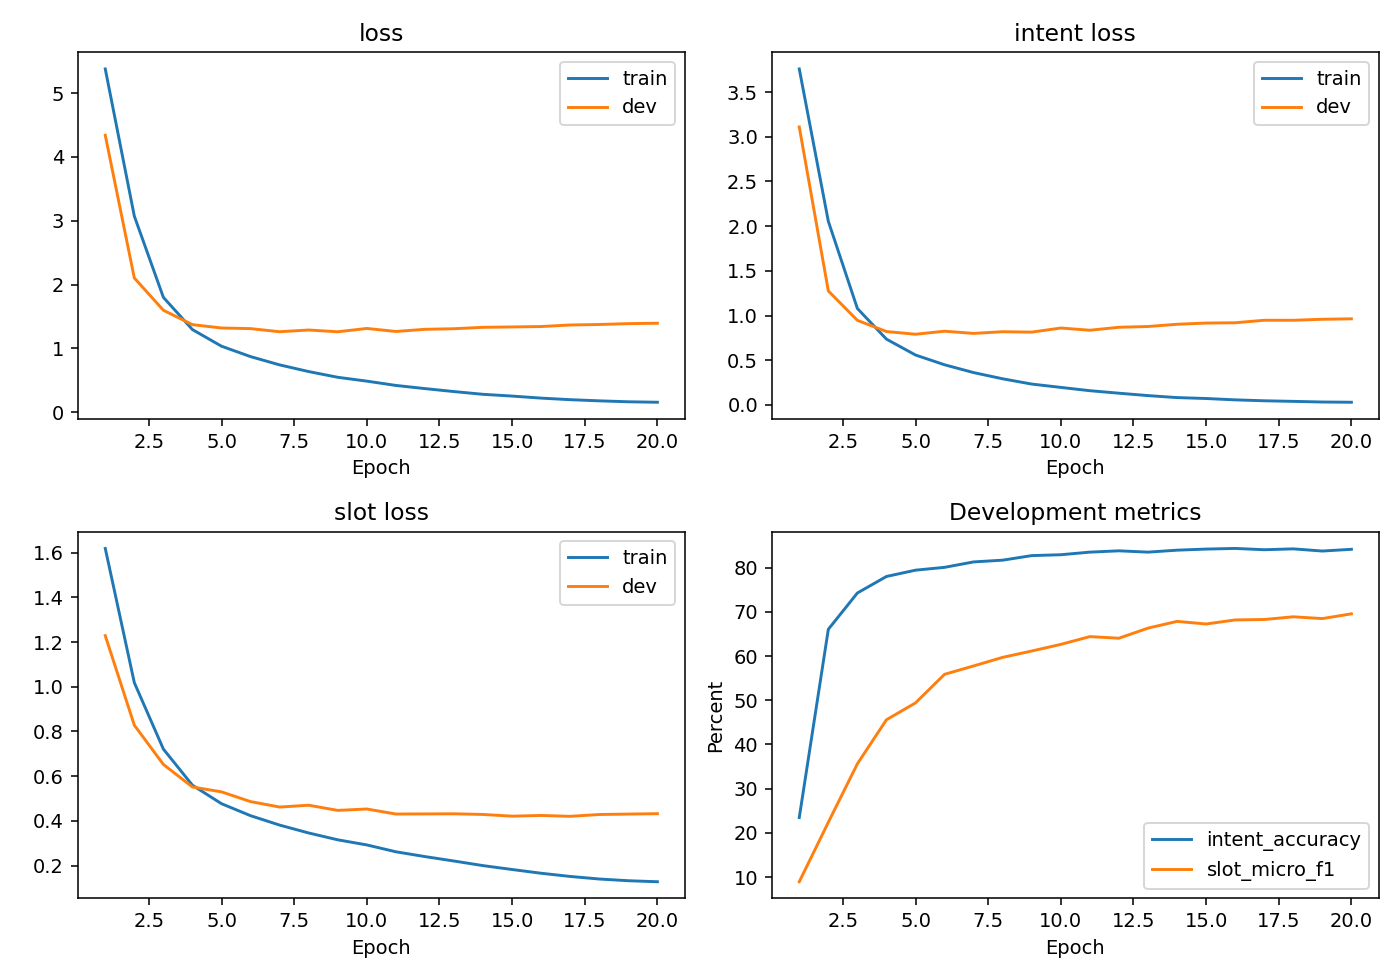

In [11]:
stage1 = run_stage('stage1', STAGE1_CONFIG, RUNTIME, RUN_OPTIONS, bundle, embedding_matrix,
    DEVICE, RUN_ROOT / 'stage1', DATASET_PATH, CODE_SHA256, NOTEBOOK_PATH)
display(Image(filename=str(RUN_ROOT / 'stage1/learning_curves.png')))


## Train the revised Transformer from fresh initialization

stage2 epoch 01/20: train=3.71057; dev=1.43269; intent=74.62; slot=45.53; mean=60.07; selected=True


stage2 epoch 02/20: train=1.31893; dev=1.15385; intent=78.90; slot=61.55; mean=70.22; selected=True


stage2 epoch 03/20: train=1.02638; dev=1.01320; intent=80.32; slot=65.89; mean=73.11; selected=True


stage2 epoch 04/20: train=0.80505; dev=0.99858; intent=82.00; slot=69.08; mean=75.54; selected=True


stage2 epoch 05/20: train=0.66728; dev=0.99097; intent=83.28; slot=70.10; mean=76.69; selected=True


stage2 epoch 06/20: train=0.56378; dev=1.03170; intent=82.29; slot=71.93; mean=77.11; selected=True


... (10 outputs left out)

stage2 epoch 17/20: train=0.09759; dev=1.33664; intent=85.74; slot=77.50; mean=81.62; selected=True


stage2 epoch 18/20: train=0.08651; dev=1.37150; intent=85.54; slot=77.91; mean=81.72; selected=True


stage2 epoch 19/20: train=0.07919; dev=1.37507; intent=85.83; slot=77.76; mean=81.80; selected=True


stage2 epoch 20/20: train=0.06724; dev=1.41805; intent=85.49; slot=77.33; mean=81.41; selected=False


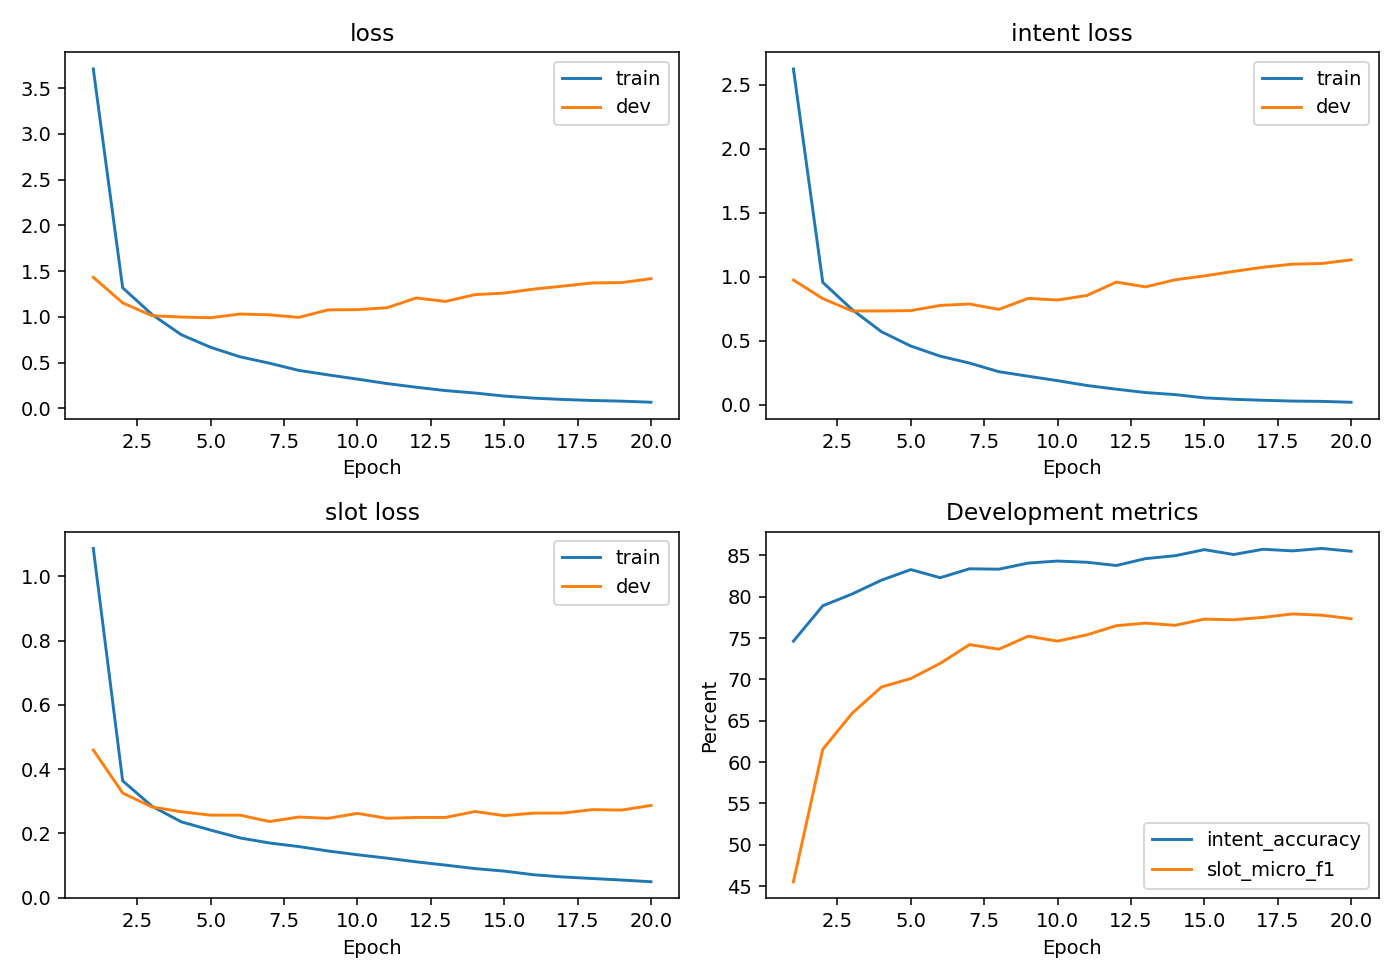

In [12]:
stage2 = run_stage('stage2', STAGE2_CONFIG, RUNTIME, RUN_OPTIONS, bundle, embedding_matrix,
    DEVICE, RUN_ROOT / 'stage2', DATASET_PATH, CODE_SHA256, NOTEBOOK_PATH)
display(Image(filename=str(RUN_ROOT / 'stage2/learning_curves.png')))


## Genuine comparison, errors and completion

Results use newly trained, development-selected and independently reloaded checkpoints. Preserve improvements and regressions. Two rows mean development-only; four rows include final test after each model was frozen. Error cases come from saved revised development predictions; proposed causes are inferences. This is a single-seed comparison of whole systems, not a controlled causal claim for any one addition.

In [13]:
results = report_results({'stage1': stage1, 'stage2': stage2}, RUN_ROOT, bundle)
print('GENERATED_RESULTS:', json.dumps(results, indent=2))
print('GENUINE_DEVELOPMENT_ERRORS:', (RUN_ROOT / 'error_cases.json').read_text(encoding='utf-8'))
completion = {'status': 'complete', 'mode': 'final' if RUN_OPTIONS['evaluate_test'] else 'development_only',
    'evaluator_version': EVALUATOR_VERSION, 'dataset_sha256': DATASET_SHA256,
    'code_sha256': CODE_SHA256, 'configuration_sha256': configuration['configuration_sha256'],
    'dataset_identity': dataset_manifest, 'stages': {'stage1': stage1, 'stage2': stage2},
    'results': 'results.json', 'new_model_test_evaluations': {
        'stage1': stage1['test_model_evaluations'], 'stage2': stage2['test_model_evaluations']}}
assert len(results['rows']) == (4 if RUN_OPTIONS['evaluate_test'] else 2)
assert all(value['status'] == 'complete' for value in (stage1, stage2))
rt_write_json(RUN_ROOT / 'completion.json', completion)
print('REVISED_TRANSFORMER_COMPLETION:', json.dumps({key: completion[key] for key in ['status','mode','evaluator_version','new_model_test_evaluations']}))


GENERATED_RESULTS: {
  "evaluator_version": "exact_character_span_v2",
  "dataset_sha256": "c70f75c6a543a26e249ec383df67733ad9b1066f6c0406c2e04a3f03356e407e",
  "rows": [
    {
      "model_version": "stage1",
      "split": "dev",
      "total_parameters": 4345243,
      "trainable_parameters": 4345243,
      "intent_accuracy_percent": "84.16",
      "slot_micro_f1_percent": "69.56",
      "epochs_trained": 20,
      "selected_epoch": 20
    },
    {
      "model_version": "stage2",
      "split": "dev",
      "total_parameters": 19748595,
      "trainable_parameters": 19748595,
      "intent_accuracy_percent": "85.83",
      "slot_micro_f1_percent": "77.76",
      "epochs_trained": 20,
      "selected_epoch": 19
    }
  ],
  "full_precision": {
    "stage1": {
      "dev": {
        "intent_accuracy": 0.8416133792424988,
        "slot_micro_f1": 0.6956095168015698,
        "slot_tp": 1418,
        "slot_fp": 647,
        "slot_fn": 594,
        "num_examples": 2033,
        "correct_

## What to report and what remains uncertain

Use this run's actual CSV/JSON, selected/trained epochs, complete parameter counts, measured memory/time, plots and genuine errors. Do not copy old scores or invent logs. If revised development performance does not improve, report the failed hypothesis and revisit training/development evidence in a separately registered run. Test remains reporting-only. Full-vocabulary Word2Vec lookup and pretrained encoders are deliberately excluded; token duplication/augmentation and external task examples are not used.

All Python source is inline. The builder's provenance is informational at runtime; no development source file, historical checkpoint or saved score is loaded. Only the verified original dataset and optional allowed word-vector asset are external inputs.

## Measured development qualification (2 November 2026)

These are genuine 20-epoch runs with common original data, initialization and scorer; no test model pass occurred.

| Model | Total/trainable parameters | Selected/trained epoch | Dev intent | Dev slot F1 | Workflow seconds |
| --- | ---: | --- | ---: | ---: | ---: |
| Original-size Transformer | 4,345,243 | 20 / 20 | 84.16% | 69.56% | 222.14 |
| Revised Transformer | 19,748,595 | 19 / 20 | 85.83% | 77.76% | 616.44 |

Revised minus baseline: **+1.67 intent points**, **+8.20 slot-F1 points**, and **+4.94 points** in their mean. This is a single-seed whole-system comparison. It does not prove statistical significance or which individual component caused the improvement.


## Remaining weaknesses after the revision

| Development group | Records | Baseline intent / slot F1 | Revised intent / slot F1 |
| --- | ---: | --- | --- |
| No-Train-OOV | 1669 | 87.18% / 75.90% | 89.10% / 83.71% |
| NonSlot-Train-OOV | 149 | 57.05% / 59.02% | 55.70% / 67.06% |
| Slot-Train-OOV | 215 | 79.53% / 34.13% | 81.40% / 43.70% |

On the same development records, the revision corrects 98 intents and regresses 64; it recovers 164 gold slot occurrences and loses 68. Fully correct utterances increase from 1189 to 1318. Non-slot-OOV intent accuracy still regresses, and slot-OOV F1 remains low. These descriptive groups do not isolate causal effects.

Two genuine remaining errors from the saved revised predictions:

- **Record 67:** `i'd like to hear queen's barcelona`. Gold is artist `queen's` and song `barcelona`; predicted intent is correctly `play_music`, but the model merges `queen's barcelona` into one artist span. **Inference:** legal BIO structure does not resolve adjacent entities with ambiguous semantics.
- **Record 30:** `cleaning is good dust is so bad do now your magic clean my carpet`. Gold is `iot_cleaning` with `house_place=carpet`; prediction is `general_quirky` without slots. **Inference:** long, loosely structured wording may obscure the action/domain; this example alone does not establish the cause.

Future work should compare independently registered capacity/character/CRF/context ablations and additional seeds using train/development only. More capacity did not remove unfamiliar-entity or intent ambiguity. No test results were used to design or choose this revision.
